# Plan noise vs plan-first prompting for code — Claim-C analysis demo (Qwen3-8B)

**Artifact `art_jR6Pyy3W9xum`** (iteration 5, experiment 27). Qwen3-8B nearly always writes one *default* algorithm
per coding task: a full sort for the k-th smallest value, Dijkstra for a weighted shortest path. This experiment asks
which knob buys **correct algorithmic diversity** most cheaply:

| family | arms | what changes |
|---|---|---|
| reference | `TWIN`, `PLAIN` | a neutral sentence + the task (`TWIN`), or the task alone (`PLAIN`) |
| **plan noise (PN)** | `PN_a1`, `PN_a2`, `PNPLAIN_a1` | an isotropic random direction added to the hidden states at the task-specification positions of decoder blocks 12–23, during the prompt prefill only, with size α·‖h‖·r_Q (α = 1, 2) |
| text-level plan samplers | `IFG_hot`, `IFG_paper`, `PSL`, `EAP`, `BINT` | the model first writes a plan in text: an intent sentence (IFG), observations → plan (PlanSearch-lite), a list of algorithms with an external random pick (enumerate-and-pick), or an intent written by **Qwen3-8B-Base** (BINT) |
| decoding | `DMD_a1`, `DMD_a2`, `T1.3`, `TOPK10` | departure-matched decoding (a temperature on generated tokens 1–32, bisected to PN's per-token KL), temperature 1.3, top-k 10 |
| prompt | `NOVELTY`, `SEMSEED` | "Write a novel algorithm for this task…", or a story paragraph prepended to the task (semantic seed) |

All arms of one **slot** (task × template W1–W5 × k) share the same code-stage random numbers (exact inverse-CDF
common random numbers, CRN). Every program is labelled by frozen mechanism labellers (runtime trace + AST). Each knob
is then priced on a **randomisation hull**. **H5** is the largest correct-only Hill-1 diversity (rarefied at depth 25)
that a mixture of the knob's settings reaches while losing at most 5 pass-rate points against `TWIN`.

**Claim C (pre-registered rule).** PN is SUPPORTED if H5(PN) ≥ the best text sampler's H5 on ≥ 3 of the 5 decisive
tasks (T03, T10, T2, T05, T1), otherwise DISCONFIRMED. The full run is **DISCONFIRMED**: PN wins only T03, and the
base-written intent beats PN on T10, T2 and T05.

### What this notebook runs

`method.py` is an orchestrator: 14 stages, each a script under `src/`. The generation stages need Qwen3-8B on a
24 GB GPU (about 2 GPU-hours on the HF bf16 engine, plus vLLM for the literal cell) and OpenRouter judges, so they
cannot run here. Their output rows are loaded from `mini_demo_data.json`. That file holds all 50 CRN slots of the
decisive tasks **T03** (k-th smallest) and **T2** (shortest path), with every arm's frozen label, pass flag,
generated code, intents and EAP lists: 1,550 programs. The notebook then runs the CPU stages on those rows, using the
original code:

1. **`analyze` → `src/analysis_c.py`** (with `src/hull_exp20.py` and `src/hull_full.py`): cell statistics,
   full-simplex hull prices H5/P15/P20, the slot bootstrap, the Claim-C rule, PN vs DMD (exact McNemar), PN plain vs
   twin, unit ratio, landings and the knob table.
2. **`rederive` → `audit/rederive.py`**: an independent re-derivation (pandas + a direct-simulation hull) and two
   placebos that must fail.

Every place where the notebook had to change the original code (to read the loaded `data` instead of files, or to
use the config sizes) is marked with a `# Notebook:` comment.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (the version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/cfg.py, src/analysis_c.py, src/hull_exp20.py, src/hull_full.py, src/parsers.py
import hashlib
import itertools
import json
import math
import multiprocessing as mp
import re
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor
from datetime import datetime, timezone
from typing import Any

import numpy as np

# audit/rederive.py
import random

import pandas as pd

# notebook: plots
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-5/experiment-27/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"{len(data['examples'])} CRN slots, {sum(len(e['rows']) for e in data['examples'])} labelled programs")
for t, d in data["metadata"]["tasks"].items():
    print(f"  {t}: {d}")

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
100 CRN slots, 1550 labelled programs
  T03: k-th smallest value in a list (default algorithm: full sort)
  T2: shortest path length in a directed weighted graph (default algorithm: Dijkstra)


## Configuration

Every size the analysis uses is set here. The full-run values are in the comments, and everything runs at its
full-run size except the bootstrap replicate count.

- With `PRICE_N_DRAWS = 1000` and `N_RAREFY = 1000`, every point estimate (cell pass rates and Hill numbers, hull
  prices) is the committed one: the same rows, seeds and CRN draws as the full run. The results section checks this.
- `N_BOOT_D5 = 500` slot-bootstrap replicates per decisive task (the full run used 2,000). It sets the precision of
  P(PN ≥ best text) and of the bootstrap intervals, not the point estimates.
  - The replicate seeds are the full run's, so these are its first 500 replicates.
  - `N_BOOT_D5 = 2000` reproduces the committed bootstrap. This was checked: P(PN ≥ best text) = 0.582 on T03 and
    0.059 on T2, with identical class intervals. It costs about 0.1 s per replicate and task on a fast CPU core, so
    about 4× this cell's run time.
- `N_WORKERS = 1`: see the bootstrap cell.

In [5]:
# ---- tunable sizes (full-run values in the comments) ----
PRICE_N_DRAWS = 1000   # CRN draws behind every point-estimate hull price (original: 1000)
N_RAREFY = 1000        # subsamples of the rarefied Hill-1 of each cell (original: 1000)
N_BOOT_D5 = 500        # slot-bootstrap replicates per decisive task (original: 2000)
N_BOOT_ND = 500        # replicates per non-decisive task (original: 500; no ND10 rows in this demo)
BOOT_RAREFY = 200      # CRN draws inside each bootstrap replicate's hull (original: 200)
N_WORKERS = 1          # bootstrap processes (original: 12; keep 1 in a notebook, see the bootstrap cell)
REDERIVE_DRAWS = 400   # direct-simulation draws per mixture in the re-derivation (original: 400)
N_SHUFFLES = 20        # arm-shuffle placebo replicates (original: 20)
SHUFFLE_DRAWS = 150    # draws per mixture inside each placebo replicate (original: 150)

## The orchestrator: `method.py`

`method.py` runs the experiment as 14 stages. Each stage is a script under `src/` that resumes from what is already
on disk, and the vLLM stage runs in its own virtualenv. The cell below is the original orchestrator, with one change:
`ROOT` is the working directory, because a notebook has no `__file__`.

`main()` is defined but not called here, since it needs the repository's scripts, two virtualenvs and a GPU. Instead,
the table printed below shows where each stage went:

- `gpu` and `label` produced the rows in `mini_demo_data.json`.
- `analyze` (Claim C) and `rederive` run inline in the rest of this notebook.

In [6]:
ROOT = Path.cwd()  # Notebook: method.py uses Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
PYV = str(ROOT / ".venv_vllm" / "bin" / "python")
(ROOT / "logs").mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

STAGES: dict[str, list[list[str]]] = {
    "s0": [[PY, "src/s0.py", "all"]],
    "prompts": [[PY, "src/prompts5.py"]],
    "commit0F": [[PY, "src/prereg5.py", "commit0F"]],
    "literal": [[PYV, "src/vllm_literal.py", "all"]],
    "label_f": [[PY, "src/label_worker_v4.py", "--raw", "data/literal_samples.jsonl", "--out",
                 "data/literal_labels.jsonl", "--name", "label_literal"]],
    "gpu": [[PY, "src/gen5.py", "base,tests,calib,ec,knobs"]],
    "commit0C": [[PY, "src/prereg5.py", "commit0C"]],
    "commit1": [[PY, "src/prereg5.py", "commit1"]],
    "label": [[PY, "src/label5.py"],
              [PY, "src/label_worker_v4.py", "--raw", "data/engine_check_raw.jsonl", "--out",
               "data/engine_check_labels.jsonl", "--name", "label_ec"]],
    "audit": [[PY, "src/audit5.py", "all"]],
    "analyze": [[PY, "src/analysis_f.py"], [PY, "src/analysis_ec.py"], [PY, "src/analysis_c.py"]],
    "figures": [[PY, "src/figures5.py"]],
    "outputs": [[PY, "src/outputs5.py"]],
    "rederive": [[PY, "audit/rederive.py"]],
}
ORDER = ["s0", "prompts", "commit0F", "literal", "label_f", "gpu", "commit0C", "commit1", "label", "audit",
         "analyze", "figures", "outputs", "rederive"]


@logger.catch(reraise=True)
def main() -> None:
    want = ORDER if len(sys.argv) < 2 or sys.argv[1] == "all" else sys.argv[1].split(",")
    for st in want:
        if st not in STAGES:
            raise SystemExit(f"unknown stage {st}; choose from {ORDER}")
        if st == "gpu" and "all" in sys.argv[1:]:
            logger.warning("the gpu stage blocks on commit0C/commit1: run commit0C and commit1 from a second shell "
                           "once calibration has finished (results/calib_done.flag)")
        for cmd in STAGES[st]:
            t0 = time.time()
            logger.info(f"[{st}] {' '.join(cmd[1:])}")
            r = subprocess.run(cmd, cwd=str(ROOT))
            if r.returncode != 0:
                logger.error(f"[{st}] failed with exit code {r.returncode}")
                raise SystemExit(r.returncode)
            logger.info(f"[{st}] done in {time.time() - t0:.0f}s")


# Notebook: main() is not called (it needs src/, .venv, .venv_vllm and a GPU). Where each stage went in this demo:
WHERE = {"src/gen5.py": "GPU: produced the knob rows -> loaded from mini_demo_data.json",
         "src/label5.py": "labels of the knob rows -> loaded from mini_demo_data.json",
         "src/analysis_c.py": "RUN BELOW (sections 8.1-8.9)", "audit/rederive.py": "RUN BELOW (re-derivation)"}
for st in ORDER:
    for cmd in STAGES[st]:
        print(f"{st:9s} {' '.join(cmd[1:])[:60]:60s} {WHERE.get(cmd[1], 'not run here')}")

s0        src/s0.py all                                                not run here
prompts   src/prompts5.py                                              not run here
commit0F  src/prereg5.py commit0F                                      not run here
literal   src/vllm_literal.py all                                      not run here
label_f   src/label_worker_v4.py --raw data/literal_samples.jsonl --ou not run here
gpu       src/gen5.py base,tests,calib,ec,knobs                        GPU: produced the knob rows -> loaded from mini_demo_data.json
commit0C  src/prereg5.py commit0C                                      not run here
commit1   src/prereg5.py commit1                                       not run here
label     src/label5.py                                                labels of the knob rows -> loaded from mini_demo_data.json
label     src/label_worker_v4.py --raw data/engine_check_raw.jsonl --o not run here
audit     src/audit5.py all                                     

## Shared utilities (`src/cfg.py`) and the common random numbers

These are exp19's shared helpers, copied verbatim: a stable 63-bit seed from the sha256 of a key, and JSON writers
that store `inf`/`nan` as `null`. The analysis writes its outputs to `results/`, as in the repository.

Every arm of a slot draws its code-stage tokens from the **same** uniform stream `u_stream(task, w, k)`, seeded by
`stable_seed(task, w, k)`. Two arms of one slot therefore differ only by their knob, not by sampling luck. The last
line checks this design on the loaded rows.

In [7]:
# src/cfg.py (verbatim). Notebook: only the two output folders the analysis writes are created.
RESULTS_DIR = ROOT / "results"
LOG_DIR = ROOT / "logs"
for _d in (RESULTS_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)
D_MODEL = 4096


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


# CRN check: the u_seed stored with every generated row is stable_seed(task, template, slot) -- shared by all arms
print("u_seed == stable_seed(task, w, k) for every row:",
      all(r["u_seed"] == stable_seed(r["task"], r["template"], r["slot"]) for ex in data["examples"] for r in ex["rows"]))

u_seed == stable_seed(task, w, k) for every row: True


## Frozen iteration-5 constants (`src/cfg5.py`)

These are the decisive tasks D5, the arm table `ARMS5` and the analysis constants committed before the first decisive
sample. `CLASS_SETTINGS` defines each knob **class** priced by the hull. `TWIN` always comes first, as the reference
operating point. For example, the PN class mixes `TWIN`, `PN_a1` and `PN_a2`. The bootstrap and rarefaction sizes come
from the config cell.

In [8]:
# src/cfg5.py (verbatim). Notebook: N_RAREFY, N_BOOT_D5, N_BOOT_ND and BOOT_RAREFY are set in the config cell.
D5 = ("T03", "T10", "T2", "T05", "T1")
ND10 = ("T04", "T06", "T08", "T11", "T13", "T14", "R1", "R2", "R3", "R6")
TASKS15 = D5 + ND10

ARMS5: dict[str, dict[str, Any]] = {
    "TWIN": {"kind": "twin", "T": 1.0, "family": "REF", "decode": "shared"},
    "PLAIN": {"kind": "plain", "T": 1.0, "family": "REF_PLAIN", "decode": "shared"},
    "PN_a1": {"kind": "twin", "T": 1.0, "alpha": 1.0, "family": "PN", "decode": "pn"},
    "PN_a2": {"kind": "twin", "T": 1.0, "alpha": 2.0, "family": "PN", "decode": "pn"},
    "PNPLAIN_a1": {"kind": "plain", "T": 1.0, "alpha": 1.0, "family": "PNPLAIN", "decode": "pn"},
    "IFG_hot": {"kind": "ifg", "T": 0.7, "t_intent": 1.3, "family": "IFG", "decode": "shared"},
    "IFG_paper": {"kind": "ifg", "T": 0.60, "t_intent": 0.73, "family": "IFG", "decode": "shared"},
    "BINT": {"kind": "ifg", "T": 0.7, "t_intent": 1.3, "family": "BINT", "decode": "leftpad"},
    "PSL": {"kind": "psl", "T": 0.9, "top_p": 0.95, "family": "PSL", "decode": "multi"},
    "EAP": {"kind": "eap", "T": 1.0, "family": "EAP", "decode": "multi"},
    "DMD_a1": {"kind": "twin", "T": 1.0, "dmd_alpha": 1.0, "family": "DMD", "decode": "shared"},
    "DMD_a2": {"kind": "twin", "T": 1.0, "dmd_alpha": 2.0, "family": "DMD", "decode": "shared"},
    # P3 reruns (bf16 engine: iteration-4 FP8 rows are not reusable slot for slot)
    "T1.3": {"kind": "twin", "T": 1.3, "family": "TEMP", "decode": "shared"},
    "TOPK10": {"kind": "twin", "T": 1.0, "top_k": 10, "family": "TOPK10", "decode": "shared"},
    "NOVELTY": {"kind": "novelty", "T": 1.0, "family": "NOVELTY", "decode": "shared"},
    "SEMSEED": {"kind": "semseed", "T": 1.0, "family": "SEMSEED", "decode": "shared"},
}
PN_BLOCKS = list(range(12, 24))

DEPTH = 25
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)
CLAIM_C_MIN_WINS = 3
UNRESOLVED_BAND = (0.2, 0.8)
MOVE_EXCESS = 0.10
MOVE_FISHER_P = 0.05
BOOT_SEED5 = 20261021
TEXT_SAMPLERS = ("IFG", "PSL", "EAP", "BINT")
CLASS_SETTINGS: dict[str, list[str]] = {
    "PN": ["TWIN", "PN_a1", "PN_a2"],
    "PN+": ["TWIN", "PN_a1", "PN_a2", "PLAIN", "PNPLAIN_a1"],
    "IFG": ["TWIN", "IFG_hot", "IFG_paper"],
    "IFG_hot_only": ["TWIN", "IFG_hot"],
    "PSL": ["TWIN", "PSL"],
    "EAP": ["TWIN", "EAP"],
    "BINT": ["TWIN", "BINT"],
    "DMD": ["TWIN", "DMD_a1", "DMD_a2"],
    "TEMP": ["TWIN", "T1.3"],
    "TOPK10": ["TWIN", "TOPK10"],
    "NOVELTY": ["TWIN", "NOVELTY"],
    "SEMSEED": ["TWIN", "SEMSEED"],
}

## What the GPU stage produced: one slot across all arms

`src/gen5.py` decoded every arm of a slot on the bf16 HF engine with the slot's shared uniform stream. Plan noise is a
prefill-only edit of the hidden states, applied by `src/hooks.py` at the task-specification positions [a, b) of blocks
12–23:

```python
# src/hooks.py, make_edits(kind="RAND", ...): displacement-targeted edit (no compounding across blocks)
hs = h[:, a:b].float()
comp = (hs - h_ref[l]) @ ul          # current displacement from the clean twin along the unit direction u_l
coef = alpha * n[l] - comp           # n[l, p] = ||h_clean[l, p]|| * r_Q((l + 1) / 36): the ban-free unit
new = hs + coef[..., None] * ul      # -> displacement along u_l is exactly alpha * n[l, p]
```

The direction `u` is one isotropic N(0, I₄₀₉₆) draw per slot, seeded by `stable_seed(task, 'PN5', w, k)`. It is shared
by `PN_a1`, `PN_a2` and `PNPLAIN_a1`. The size factor r_Q is exp23's median ratio of a ban edit to the hidden-state
norm at each relative depth. The edit itself needs the 8B model, but the direction and the unit factor are plain
numpy (`src/gen5.py`). The first cell below runs them and checks them against the seeds logged with every PN row.

The second cell prints slot **T2 | W1 | k = 4** (shortest path) for every arm. With the same random numbers,
`PN_a2` is the arm that writes a Bellman-Ford/SPFA program instead of Dijkstra, and it still passes every hidden test.

In [9]:
# src/gen5.py (verbatim): the r_Q factor of the ban-free unit and the per-slot PN direction
def r_q_table() -> tuple[np.ndarray, np.ndarray]:
    q = data["metadata"]["aux_inputs"]["exp23_r_Q"]  # Notebook: inputs/exp23/results/qwen_ratio.json "r_Q"
    d = np.array([v["depth"] for v in q.values()])
    r = np.array([v["median"] for v in q.values()])
    o = np.argsort(d)
    return d[o], r[o]


_RQ = None


def r_at(l: int) -> float:
    global _RQ
    if _RQ is None:
        _RQ = r_q_table()
    return float(np.interp((l + 1) / 36, _RQ[0], _RQ[1]))


def pn5_direction(task: str, w: str, k: int, tag: str = "PN5") -> tuple[int, np.ndarray]:
    seed = stable_seed(task, tag, w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


# -- notebook: the seeds logged with the PN rows are these directions; the push size per block is alpha * r_Q * ||h||
pn_rows = [r for ex in data["examples"] for r in ex["rows"] if r["arm"] in ("PN_a1", "PN_a2", "PNPLAIN_a1")]
print(f"direction_seed == stable_seed(task, 'PN5', w, k) for all {len(pn_rows)} PN rows:",
      all(r["direction_seed"] == pn5_direction(r["task"], r["template"], r["slot"])[0] for r in pn_rows))
seed, u = pn5_direction("T2", "W1", 4)
print(f"slot T2|W1|4: u in R^{u.size}, ||u|| = {np.linalg.norm(u):.4f}, first entries {np.round(u[:4], 4)}")
print("r_Q((l+1)/36) at the hooked blocks:", {l: round(r_at(l), 3) for l in PN_BLOCKS})
for r in pn_rows:
    if (r["task"], r["template"], r["slot"]) == ("T2", "W1", 4):
        print(f"  {r['arm']:10s} alpha={r['alpha']}: realised displacement vs the clean twin "
              f"(S = spec positions, R = read position; b = block) {r['realised_disp']}")

direction_seed == stable_seed(task, 'PN5', w, k) for all 300 PN rows: True
slot T2|W1|4: u in R^4096, ||u|| = 1.0000, first entries [-0.0185 -0.015   0.0047 -0.0012]
r_Q((l+1)/36) at the hooked blocks: {12: 0.07, 13: 0.078, 14: 0.083, 15: 0.092, 16: 0.096, 17: 0.104, 18: 0.113, 19: 0.115, 20: 0.12, 21: 0.123, 22: 0.119, 23: 0.115}
  PN_a1      alpha=1.0: realised displacement vs the clean twin (S = spec positions, R = read position; b = block) {'S_b12': 4.5357, 'S_b23': 44.2617, 'S_b35': 174.8425, 'R_b23': 21.6437, 'R_b35': 116.5982, 'relerr_u_max': 0.000223}
  PN_a2      alpha=2.0: realised displacement vs the clean twin (S = spec positions, R = read position; b = block) {'S_b12': 9.0697, 'S_b23': 89.4196, 'S_b35': 360.8887, 'R_b23': 43.9156, 'R_b35': 225.8858, 'relerr_u_max': 0.00015}
  PNPLAIN_a1 alpha=1.0: realised displacement vs the clean twin (S = spec positions, R = read position; b = block) {'S_b12': 4.5785, 'S_b23': 45.1773, 'S_b35': 186.2292, 'R_b23': 21.5098, 'R_b35': 119.0

In [10]:
# One CRN slot across every arm: final-program label, pass flag, and the text-level plan when the arm writes one
ex = next(e for e in data["examples"] if (e["task"], e["template"], e["slot"]) == ("T2", "W1", 4))
for r in sorted(ex["rows"], key=lambda r: list(ARMS5).index(r["arm"])):
    plan = (r.get("intent") and f"intent: {r['intent']}") or (r.get("picked_name") and f"EAP pick: {r['picked_name']}") \
        or (r.get("pair") and f"PSL plan from observations {r['pair']}") or ""
    knob = r.get("temperature_schedule") or f"T={r['temperature']}" + (f", alpha={r['alpha']}" if r.get("alpha") else "") \
        + (f", top_k={r['top_k']}" if r.get("top_k") else "")
    print(f"{r['arm']:11s} {knob:36s} {r['label']:>9s} {'pass' if r['passed'] else 'FAIL'}  {plan[:70]}")

by_arm = {r["arm"]: r for r in ex["rows"]}
for a in ("TWIN", "PN_a2"):
    print(f"\n----- {a} ({by_arm[a]['label']}), first 14 lines -----")
    print("\n".join(by_arm[a]["code"].splitlines()[:14]))

TWIN        T=1.0                                 dijkstra pass  
PLAIN       T=1.0                                 dijkstra pass  
PN_a1       T=1.0, alpha=1.0                      dijkstra pass  
PN_a2       T=1.0, alpha=2.0                       bf_spfa pass  
PNPLAIN_a1  T=1.0, alpha=1.0                      dijkstra pass  
IFG_hot     T=0.7                                 dijkstra pass  intent: Use Dijkstra's algorithm to find the shortest path from node s
IFG_paper   T=0.6                                 dijkstra pass  intent: Use Dijkstra's algorithm to find the shortest path from node s
BINT        T=0.7                                 dijkstra pass  intent: Use Dijkstra's algorithm to find the shortest path in a direct
PSL         T=0.9                                 dijkstra pass  PSL plan from observations [2, 5]
EAP         T=1.0                                 dijkstra pass  EAP pick: BFS with priority queue
DMD_a1      T=2.0122 for tokens 1-32, then 1.0    dijkstra pass 

## Diversity and the randomisation hull (`src/hull_exp20.py`, exp20's code, verbatim)

**Hill-1** is the exponential of the Shannon entropy of the correct programs' algorithm labels. It equals 1 when every
correct program uses the same algorithm, and 2 for an even split between two algorithms. It is *rarefied* at depth 25
(mean over subsamples of 25 correct programs), so that cells with different pass counts are comparable.

The **randomisation hull** mixes the settings of one knob class with weights w on the simplex, in the style of
Provost-Fawcett operating-point mixing:

- `cost(w) = pass_TWIN − Σ_j w_j·pass_j`.
- `Hill(w)` comes from a two-stage draw: 25 programs are allocated to the settings by a multinomial with π_j ∝ w_j·pass_j,
  then each setting's share is drawn from its correct programs.
- `HullSampler` pre-draws all of that randomness once (common random numbers across w), so mixtures are compared
  without Monte-Carlo noise between them.

In [11]:
# src/hull_exp20.py (verbatim; exp20's hull_prices and C1-site rule are not used by this artifact's analysis)
DEPTH = 25
GRID_STEP = 0.05
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)


def hill1(counts: np.ndarray) -> np.ndarray:
    """exp(Shannon entropy) along the last axis of a count array."""
    c = np.asarray(counts, dtype=np.float64)
    n = c.sum(-1, keepdims=True)
    p = np.where(n > 0, c / np.maximum(n, 1e-12), 0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.where(p > 0, p * np.log(p), 0.0).sum(-1)
    return np.exp(h)


def rarefied_hill(labels: list[str], depth: int = DEPTH, n_sub: int = 1000, seed: int = 0) -> dict[str, Any]:
    """Rarefied Hill-1; cells with fewer than `depth` correct programs report Hill at their own depth (flagged)."""
    n = len(labels)
    if n == 0:
        return {"hill": None, "depth": 0, "flag_own_depth": True, "n": 0}
    cats, inv = np.unique(np.array(labels), return_inverse=True)
    counts = np.bincount(inv, minlength=len(cats))
    m = min(depth, n)
    rng = np.random.default_rng(seed)
    sub = rng.multivariate_hypergeometric(counts, m, size=n_sub)
    return {"hill": float(hill1(sub).mean()), "depth": int(m), "flag_own_depth": bool(m < depth), "n": int(n)}


def simplex_grid(k: int, step: float = GRID_STEP, max_nonzero: int = 3) -> np.ndarray:
    m = int(round(1 / step))
    pts = []
    for comb in itertools.product(range(m + 1), repeat=k - 1):
        s = sum(comb)
        if s <= m:
            w = list(comb) + [m - s]
            if sum(1 for x in w if x > 0) <= max_nonzero:
                pts.append(w)
    return np.array(pts, dtype=np.float64) / m


class HullSampler:
    """Pre-draws the CRN randomness for one (task, site): per draw d, 25 uniforms (multinomial allocation by inverse
    CDF on pi(w)) and, per setting j, an ordered sequence of 25 correct programs (a random permutation, then draws with
    replacement beyond N_correct_j). C[j][d, n, :] = label counts among the first n programs of setting j in draw d."""

    def __init__(self, settings: list[dict[str, Any]], n_draws: int = 1000, depth: int = DEPTH, seed: int = 0):
        self.settings = settings
        self.depth = depth
        rng = np.random.default_rng(seed)
        cats = sorted({l for s in settings for l in s["correct_labels"]})
        self.cats = cats
        ci = {c: i for i, c in enumerate(cats)}
        K = max(len(cats), 1)
        self.U = rng.random((n_draws, depth))
        self.C = []
        self.with_replacement = []
        for s in settings:
            labs = np.array([ci[l] for l in s["correct_labels"]], dtype=np.int64)
            C = np.zeros((n_draws, depth + 1, K), dtype=np.int32)
            if len(labs):
                seqs = np.empty((n_draws, depth), dtype=np.int64)
                for d in range(n_draws):
                    if len(labs) >= depth:
                        seqs[d] = rng.permutation(labs)[:depth]
                    else:
                        extra = rng.choice(labs, size=depth - len(labs), replace=True)
                        seqs[d] = np.concatenate([rng.permutation(labs), extra])
                oh = np.zeros((n_draws, depth, K), dtype=np.int32)
                np.put_along_axis(oh, seqs[..., None], 1, axis=2)
                C[:, 1:] = np.cumsum(oh, axis=1)
            self.C.append(C)
            self.with_replacement.append(bool(0 < len(labs) < depth))
        self.pass_ = np.array([s["pass"] for s in settings], dtype=np.float64)
        self.n_correct = np.array([len(s["correct_labels"]) for s in settings])

    def hill_of(self, w: np.ndarray) -> float:
        a = w * self.pass_
        if a.sum() <= 0:
            return float("nan")
        pi = a / a.sum()
        cdf = np.cumsum(pi)
        cdf[-1] = 1.0
        j_of = np.searchsorted(cdf, self.U, side="right").clip(max=len(pi) - 1)  # [D, depth]
        comp = 0
        for j in range(len(pi)):
            nj = (j_of == j).sum(1)
            if pi[j] > 0:
                comp = comp + np.take_along_axis(self.C[j], nj[:, None, None], axis=1)[:, 0]
        return float(hill1(comp).mean())

    def cost_of(self, w: np.ndarray) -> float:
        return float(self.pass_[0] - (w * self.pass_).sum())

## Full-simplex prices H5 / P15 / P20 (`src/hull_full.py`, verbatim)

`hull_prices_full` evaluates every mixture on a simplex grid (step 0.01 for ≤ 3 settings, 0.02 for 4, 0.05 for 5),
then refines locally around the best feasible point. From these mixtures it reports:

- **H5**: the maximum Hill subject to cost ≤ 0.05. This is the headline price.
- **P15 / P20**: the minimum cost that reaches Hill 1.5 / 2.0 (`inf` = never reached).
- the **frontier**: the best Hill found so far, as the cost grows.

`max_nonzero=2` gives the *edge-restricted* hull, used as a sensitivity.

In [12]:
# src/hull_full.py (verbatim; its CPU unit tests live in src/tests_cpu.py)
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)


def grid_step(k: int) -> float:
    return 0.01 if k <= 3 else (0.02 if k == 4 else 0.05)


def local_grid(w0: np.ndarray, step: float, radius: float, support_only: bool) -> np.ndarray:
    k = len(w0)
    idx = [j for j in range(k) if (w0[j] > 0 or not support_only)]
    if len(idx) <= 1:
        return w0[None]
    free = idx[:-1]
    offs = np.arange(-radius, radius + 1e-12, step)
    pts = []
    for d in itertools.product(offs, repeat=len(free)):
        w = w0.copy()
        for j, dj in zip(free, d):
            w[j] += dj
        w[idx[-1]] -= sum(d)
        if (w >= -1e-12).all():
            pts.append(np.clip(w, 0, None) / max(np.clip(w, 0, None).sum(), 1e-12))
    return np.array(pts) if pts else w0[None]


def _prices_on(hs: HullSampler, grid: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    costs = np.array([hs.cost_of(w) for w in grid])
    hills = np.array([hs.hill_of(w) for w in grid])
    return costs, hills


def hull_prices_full(settings: list[dict[str, Any]], n_draws: int = 1000, seed: int = 0, step: float | None = None,
                     max_nonzero: int | None = None, refine: bool = True, keep_frontier: bool = False,
                     refine_step: float | None = None) -> dict[str, Any]:
    k = len(settings)
    if k == 1:
        hs = HullSampler(settings, n_draws=n_draws, seed=seed)
        h = hs.hill_of(np.array([1.0]))
        return {"H5": h, "H5_mixture": [1.0], "P15": 0.0 if h >= 1.5 else math.inf,
                "P20": 0.0 if h >= 2.0 else math.inf, "frontier": [[0.0, h]] if keep_frontier else None}
    hs = HullSampler(settings, n_draws=n_draws, seed=seed)
    st = step or grid_step(k)
    grid = simplex_grid(k, st, max_nonzero=max_nonzero or k)
    costs, hills = _prices_on(hs, grid)
    ok = np.isfinite(hills)
    feas = ok & (costs <= COST_BOUND + 1e-12)
    out: dict[str, Any] = {"grid_step": st, "n_grid": int(len(grid)), "max_nonzero": int(max_nonzero or k)}
    if refine and feas.any():
        w0 = grid[feas][int(np.argmax(hills[feas]))]
        rs = refine_step or (0.0025 if k <= 3 else 0.01)
        lg = local_grid(w0, rs, 0.04, support_only=(k > 3))
        if max_nonzero is not None:
            lg = lg[(lg > 1e-12).sum(1) <= max_nonzero]
        if len(lg):
            c2, h2 = _prices_on(hs, lg)
            grid = np.vstack([grid, lg])
            costs = np.concatenate([costs, c2])
            hills = np.concatenate([hills, h2])
            ok = np.isfinite(hills)
            feas = ok & (costs <= COST_BOUND + 1e-12)
        out["n_refine"] = int(len(lg))
    out["H5"] = float(hills[feas].max()) if feas.any() else float("nan")
    out["H5_mixture"] = grid[feas][int(np.argmax(hills[feas]))].tolist() if feas.any() else None
    for tgt in HILL_TARGETS:
        m = ok & (hills >= tgt)
        out[f"P{int(tgt * 10)}"] = float(costs[m].min()) if m.any() else math.inf
    if keep_frontier:
        order = np.argsort(costs)
        fr, best = [], -1.0
        for i in order:
            if ok[i] and hills[i] > best + 1e-9:
                best = hills[i]
                fr.append([round(float(costs[i]), 4), round(float(hills[i]), 4)])
        out["frontier"] = fr
    out["with_replacement_flags"] = hs.with_replacement
    return out

## `src/analysis_c.py`: loading the rows and the frozen default

`load_rows` merges every generated row with its frozen label. In the notebook, both come from the loaded `data`.
`raw_line` restores the row order of `data/samples_raw.jsonl`. That order matters: the CRN hull sampler permutes each
cell's correct programs in this order, so it is what makes the point estimates match the committed ones exactly.

The **default** of a decisive task is this run's `TWIN` modal correct label, if its share is ≥ 0.6. Non-decisive tasks
use exp19's `TWIN` default, which comes precomputed with the demo data because this demo has no ND10 rows.

In [13]:
CLAIM_CLASSES = ["PN", "IFG", "PSL", "EAP", "BINT", "DMD", "IFG_hot_only"]
OTHER_CLASSES = ["TEMP", "TOPK10", "NOVELTY", "SEMSEED"]
LEFTPAD_ARMS = {"BINT", "PSL", "EAP"}


def load_rows(relabel: dict[str, str] | None = None) -> list[dict[str, Any]]:
    # Notebook: data/samples_raw.jsonl and data/labels.jsonl come joined in mini_demo_data.json (one example per CRN
    # slot); every row carries both files' fields, and raw_line restores the order of samples_raw.jsonl.
    demo_rows = sorted((r for ex in data["examples"] for r in ex["rows"]), key=lambda r: r["raw_line"])
    labs = {r["sample_id"]: r for r in demo_rows}
    out = []
    seen = set()
    for r in demo_rows:
        sid = r["sample_id"]
        if sid in seen:
            continue
        seen.add(sid)
        l = labs.get(sid)
        if l is None:
            continue
        lab = l.get("label") or "invalid"
        if relabel and l.get("passed") and lab == "other" and l.get("code_sha256") in relabel:
            lab = relabel[l["code_sha256"]]
        out.append({"task": r["task"], "arm": r["arm"], "w": r["template"], "k": int(r["slot"]), "label": lab,
                    "passed": bool(l.get("passed")), "valid": bool(l.get("valid", True)),
                    "engine_path": r.get("engine_path"), "code_sha256": l.get("code_sha256"),
                    "labeller_source": l.get("labeller_source"), "finish_reason": r.get("finish_reason"),
                    "intent_valid": r.get("intent_valid"), "intent_capped": r.get("intent_capped"),
                    "parse_ok": r.get("parse_ok"), "picked_name": r.get("picked_name"),
                    "enum_list": r.get("enum_list"), "unit_ratio": r.get("unit_ratio_banfree_over_ban"),
                    "realised_disp": r.get("realised_disp")})
    return out


def index(rows: list[dict[str, Any]]) -> dict[tuple[str, str], dict[tuple[str, int], dict[str, Any]]]:
    idx: dict[tuple[str, str], dict[tuple[str, int], dict[str, Any]]] = defaultdict(dict)
    for r in rows:
        idx[(r["task"], r["arm"])][(r["w"], r["k"])] = r
    return idx


def exp19_defaults() -> dict[str, dict[str, Any]]:
    # Notebook: exp19's TWIN rows (inputs/exp19/data/samples.jsonl) are not shipped. The demo data carries this
    # function's output, computed from them by the original body:
    #     rows = [r for r in read_jsonl(INPUTS / "exp19" / "data" / "samples.jsonl") if r.get("arm") == "TWIN"]
    #     per task: corr = [r["label"] for r in rs if r.get("passed")]; modal, n = Counter(corr).most_common(1)[0]
    #     out[t] = {"modal": modal, "share": n / max(len(corr), 1), "N": len(rs), "n_correct": len(corr)}
    return data["metadata"]["aux_inputs"]["exp19_twin_defaults"]


def defaults(idx) -> dict[str, dict[str, Any]]:
    e19 = exp19_defaults()
    out = {}
    for t in TASKS15:
        tw = list(idx.get((t, "TWIN"), {}).values())
        corr = [r["label"] for r in tw if r["passed"]]
        c = Counter(corr)
        modal, n = c.most_common(1)[0] if c else (None, 0)
        share = n / max(len(corr), 1)
        if t in D5:
            d = modal if (modal is not None and share >= 0.6) else None
            out[t] = {"default": d, "source": "this TWIN (N 50)", "modal": modal, "share": share, "N": len(tw)}
        else:
            e = e19.get(t, {})
            d = e.get("modal") if (e.get("modal") is not None and e.get("share", 0) >= 0.6) else None
            agree = (modal == d) if d is not None and modal is not None else None
            out[t] = {"default": d if agree is not False else None, "source": "exp19 TWIN (N 50)",
                      "exp19_modal": e.get("modal"), "exp19_share": e.get("share"), "this_modal": modal,
                      "this_share": share, "this_N": len(tw), "confirmed": agree,
                      "flag": None if agree else ("NO DEFAULT (disagreement)" if agree is False else "unconfirmed")}
    return out

## `src/analysis_c.py`: per-cell statistics and the price of a knob class

These helpers are verbatim:

- `cell_stats`: one (task, arm) cell's pass rate (Wilson interval), correct composition, off-default share and
  rarefied Hill.
- `settings_of`: collects a class's settings, with `TWIN` first.
- Amendment A1: a cell with fewer than 30 rows on a decisive task stays out of the hull.
- `price`: runs the full-simplex hull on those settings.
- `mcnemar_exact`: the exact binomial test on discordant slots, used for every paired comparison.

In [14]:
def wilson(k: int, n: int, z: float = 1.96) -> list[float | None]:
    if n == 0:
        return [None, None]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    from scipy.stats import binomtest

    b = sum(1 for a, c in zip(x, y) if a == 1 and c == 0)
    c = sum(1 for a, cc in zip(x, y) if a == 0 and cc == 1)
    p = float(binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0
    return {"n_pairs": len(x), "x_only": b, "y_only": c, "p_exact": p}


def cell_stats(rs: list[dict[str, Any]], default: str | None) -> dict[str, Any]:
    n = len(rs)
    corr = [r for r in rs if r["passed"]]
    labs = [r["label"] for r in corr]
    off = [r for r in corr if default is not None and r["label"] != default]
    rh = rarefied_hill(labs, depth=DEPTH, n_sub=N_RAREFY, seed=0) if labs else {"hill": None, "depth": 0,
                                                                                 "flag_own_depth": True, "n": 0}
    out = {"N": n, "pass": len(corr) / n if n else None, "pass_wilson95": wilson(len(corr), n),
           "n_correct": len(corr), "correct_composition": dict(Counter(labs)),
           "attempted_composition": dict(Counter(r["label"] for r in rs)),
           "invalid_rate": sum(r["label"] == "invalid" for r in rs) / n if n else None,
           "other_rate": sum(r["label"] == "other" for r in rs) / n if n else None,
           "off_default_share": len(off) / n if n else None,
           "correct_only_off_default_share": len(off) / len(corr) if corr else None,
           "hill_rarefied": rh["hill"], "hill_depth": rh["depth"], "hill_own_depth_flag": rh["flag_own_depth"],
           "cap_hits": sum(r["finish_reason"] == "length" for r in rs),
           "engine_paths": dict(Counter(r["engine_path"] for r in rs))}
    if any(r.get("intent_valid") is not None for r in rs):
        iv = [r for r in rs if r.get("intent_valid") is not None]
        out["intent_valid_rate"] = sum(bool(r["intent_valid"]) for r in iv) / len(iv)
        out["intent_capped_rate"] = sum(bool(r.get("intent_capped")) for r in iv) / len(iv)
    if any(r.get("parse_ok") is not None for r in rs):
        out["parse_ok_rate"] = sum(r.get("parse_ok") is not False for r in rs) / n
    return out


MIN_N = {"D5": 30, "ND10": 15}   # amendment A1: incomplete cells (e.g. a dropped arm's stage-100 rows) stay out


def min_n(task: str) -> int:
    return MIN_N["D5"] if task in D5 else MIN_N["ND10"]


def settings_of(idx, task: str, cls: str, slots: list[tuple[str, int]] | None = None) -> list[dict[str, Any]] | None:
    arms = CLASS_SETTINGS[cls]
    out = []
    for a in arms:
        cell = idx.get((task, a))
        if not cell or len(cell) < min_n(task):
            if a == "TWIN":
                return None
            continue
        rs = [cell[s] for s in slots if s in cell] if slots is not None else list(cell.values())
        if not rs:
            continue
        out.append({"arm": a, "correct_labels": [r["label"] for r in rs if r["passed"]],
                    "pass": sum(r["passed"] for r in rs) / len(rs)})
    if len(out) < 2 or out[0]["arm"] != "TWIN":
        return None
    return out


def price(idx, task: str, cls: str, **kw) -> dict[str, Any] | None:
    st = settings_of(idx, task, cls)
    if st is None:
        return None
    res = hull_prices_full(st, **kw)
    res["arms"] = [s["arm"] for s in st]
    return res

## `src/analysis_c.py`: the slot bootstrap

Each replicate resamples the slots k with replacement **within each template**, jointly for every arm of the task, so
the CRN pairing is kept. It then re-selects every class's best mixture: grid 0.05, a local refinement at 0.01, and
`BOOT_RAREFY` draws.

The original spreads the replicates over 12 `spawn` worker processes. Functions defined in a notebook cannot be
pickled into spawned workers, so with `N_WORKERS = 1` the replicates run in-process. They use the same seeds and give
the same replicates. Replicates are cached in `results/boot_cache/<task>.json`, keyed by the rows, the class list and
`n_boot` (amendment A3).

In [15]:
def _boot_worker(args: tuple) -> list[dict[str, float]]:
    rows, task, classes, seeds = args
    idx = index(rows)
    slots_by_w = defaultdict(set)
    for (t, a), cell in idx.items():
        if t == task:
            for (w, k) in cell:
                slots_by_w[w].add(k)
    out = []
    for sd in seeds:
        rng = np.random.default_rng(sd)
        # resample slots within each template, jointly for every arm; duplicates become distinct pseudo-slots
        mapping = []
        for w in sorted(slots_by_w):
            ks = sorted(slots_by_w[w])
            draw = rng.choice(ks, size=len(ks), replace=True)
            mapping += [(w, int(k)) for k in draw]
        rec: dict[str, float] = {}
        for cls in classes:
            arms = CLASS_SETTINGS[cls]
            st = []
            for a in arms:
                cell = idx.get((task, a))
                if not cell or len(cell) < min_n(task):
                    continue
                rs = [cell[s] for s in mapping if s in cell]
                if not rs:
                    continue
                st.append({"arm": a, "correct_labels": [r["label"] for r in rs if r["passed"]],
                           "pass": sum(r["passed"] for r in rs) / len(rs)})
            if len(st) < 2 or st[0]["arm"] != "TWIN":
                continue
            k = len(st)
            r = hull_prices_full(st, n_draws=BOOT_RAREFY, seed=int(sd % (2 ** 31)), step=0.05 if k <= 4 else 0.1,
                                 refine=True, refine_step=0.01)
            rec[cls] = r["H5"]
            rec[cls + "_P15"] = r["P15"]
            rec[cls + "_P20"] = r["P20"]
        out.append(rec)
    return out


def bootstrap(rows, task: str, classes: list[str], n_boot: int, n_workers: int) -> list[dict[str, float]]:
    """Amendment A3 (computation only): replicates are cached per task in results/boot_cache/<task>.json, keyed by the
    sha256 of the task's (sample_id, arm, slot, label, passed) rows, the class list and n_boot; identical inputs ->
    identical replicates (the seeds are fixed), so reuse changes no number."""
    import hashlib
    trows = [r for r in rows if r["task"] == task]
    key = hashlib.sha256(json.dumps([sorted((r["arm"], r["w"], r["k"], r["label"], r["passed"]) for r in trows),
                                     sorted(classes), n_boot]).encode()).hexdigest()
    cp = RESULTS_DIR / "boot_cache" / f"{task}.json"
    if cp.exists():
        c = read_json(cp)
        if c.get("key") == key:
            return c["replicates"]
    out = _bootstrap(trows, task, classes, n_boot, n_workers)
    write_json(cp, {"key": key, "replicates": out})
    return out


def _bootstrap(trows, task: str, classes: list[str], n_boot: int, n_workers: int) -> list[dict[str, float]]:
    seeds = [BOOT_SEED5 * 1000 + i + 7919 * TASKS15.index(task) for i in range(n_boot)]
    chunks = [seeds[i::n_workers] for i in range(n_workers)]
    if n_workers == 1:
        # Notebook: notebook-defined functions cannot be pickled into 'spawn' workers -> one worker runs in-process
        return [x for c in chunks if c for x in _boot_worker((trows, task, classes, c))]
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=mp.get_context("spawn")) as ex:
        parts = list(ex.map(_boot_worker, [(trows, task, classes, c) for c in chunks if c]))
    out = [x for p in parts for x in p]
    return out


def ci(vals: list[float]) -> list[float | None]:
    v = [x for x in vals if x is not None and np.isfinite(x)]
    if not v:
        return [None, None]
    return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]

## `src/analysis_c.py`: the committed Claim-C rule

`claim_c_point` is the rule as committed:

- For each decisive task, `best_text` is the largest H5 among IFG, PSL, EAP and BINT.
- PN wins the task if `round(H5_PN, 2) >= round(best_text, 2)`.
- The verdict is SUPPORTED if PN wins at least 3 of the 5 decisive tasks.
- When fewer than 5 tasks are evaluable, the threshold is ⌈0.6 × evaluable⌉. This demo has 2 decisive tasks, so the
  threshold is 2.

In [16]:
def claim_c_point(h5: dict[str, dict[str, float]], text_classes: list[str], pn_class: str = "PN",
                  tasks: tuple[str, ...] = D5, min_wins: int | None = None) -> dict[str, Any]:
    per = {}
    wins = 0
    n_eval = 0
    for t in tasks:
        hp = h5.get(t, {}).get(pn_class)
        tx = {c: h5.get(t, {}).get(c) for c in text_classes if h5.get(t, {}).get(c) is not None}
        if hp is None or not tx:
            per[t] = {"evaluable": False}
            continue
        n_eval += 1
        best_c = max(tx, key=lambda c: tx[c])
        best = tx[best_c]
        win = round(hp, 2) >= round(best, 2)
        wins += win
        per[t] = {"H5_PN": hp, "best_text": best, "best_text_class": best_c, "text_H5": tx, "PN_wins": bool(win),
                  "tie": round(hp, 2) == round(best, 2), "D_t": hp - best}
    thr = min_wins if min_wins is not None else (CLAIM_C_MIN_WINS if n_eval == len(D5) else
                                                 math.ceil(0.6 * n_eval))
    verdict = "SUPPORTED" if wins >= thr else "DISCONFIRMED"
    dts = [v["D_t"] for v in per.values() if v.get("evaluable", True) and "D_t" in v]
    return {"per_task": per, "wins": wins, "n_tasks_evaluable": n_eval, "threshold": thr, "verdict": verdict,
            "D_bar": float(np.mean(dts)) if dts else None}

## Section 8.1: rows, index and defaults

This section starts `run()` of `src/analysis_c.py`. The 1,550 rows are indexed by (task, arm) and then by slot (w, k),
and the frozen defaults are fixed: `full_sort` for T03 and `dijkstra` for T2.

In [17]:
t_run = time.time()
rows = load_rows()
idx = index(rows)
dfl = defaults(idx)
write_json(RESULTS_DIR / "defaults.json", dfl)

# -- notebook: what this section computed
print(f"{len(rows)} rows in {len(idx)} (task, arm) cells")
for t in ("T03", "T2"):
    print(t, {k: dfl[t][k] for k in ("default", "modal", "share", "N")})

1550 rows in 31 (task, arm) cells
T03 {'default': 'full_sort', 'modal': 'full_sort', 'share': 0.98, 'N': 50}
T2 {'default': 'dijkstra', 'modal': 'dijkstra', 'share': 1.0, 'N': 50}


## Section 8.2: per-cell statistics

For each (task, arm) cell this section computes the pass rate, the composition of the correct programs, the
off-default share and the rarefied Hill-1.

Read down the table:

- `TWIN`, `T1.3` and `TOPK10` stay at the default, with Hill near 1.
- Plan noise at α 2 (`PN_a2`) moves T03 to quickselect and heaps.
- `SEMSEED` moves T2 to Bellman-Ford/SPFA. Its story paragraph describes relaxation in rounds.
- `EAP` spreads furthest, but it fails more programs.

In [18]:
cells = {}
for (t, a), cell in sorted(idx.items()):
    cells[f"{t}|{a}"] = cell_stats(list(cell.values()), dfl.get(t, {}).get("default"))
write_json(RESULTS_DIR / "cells.json", cells)
write_json(RESULTS_DIR / "incomplete_cells.json",
           {k: v["N"] for k, v in cells.items() if v["N"] < min_n(k.split("|")[0])})

# -- notebook: compact view of the cells (pass rate, off-default share of N, rarefied Hill, correct composition)
f2 = lambda x: "  -  " if x is None else f"{x:.2f}"
for k, v in cells.items():
    print(f"{k:16s} N={v['N']:3d} pass={f2(v['pass'])} off-default={f2(v['off_default_share'])} "
          f"Hill={f2(v['hill_rarefied'])}  {v['correct_composition']}")

T03|BINT         N= 50 pass=0.94 off-default=0.16 Hill=1.86  {'full_sort': 39, 'counting_sort': 1, 'size_k_heap': 4, 'quickselect': 2, 'other': 1}
T03|DMD_a1       N= 50 pass=1.00 off-default=0.02 Hill=1.09  {'full_sort': 49, 'quickselect': 1}
T03|DMD_a2       N= 50 pass=0.98 off-default=0.02 Hill=1.10  {'full_sort': 48, 'quickselect': 1}
T03|EAP          N= 50 pass=0.80 off-default=0.68 Hill=3.24  {'quickselect': 24, 'size_k_heap': 2, 'full_sort': 6, 'other': 4, 'counting_sort': 4}
T03|IFG_hot      N= 50 pass=0.98 off-default=0.02 Hill=1.10  {'full_sort': 48, 'heapify_pop': 1}
T03|IFG_paper    N= 50 pass=1.00 off-default=0.04 Hill=1.19  {'full_sort': 48, 'heapify_pop': 1, 'quickselect': 1}
T03|NOVELTY      N= 50 pass=0.96 off-default=0.96 Hill=1.10  {'quickselect': 47, 'heapify_pop': 1}
T03|PLAIN        N= 50 pass=1.00 off-default=0.00 Hill=1.00  {'full_sort': 50}
T03|PNPLAIN_a1   N= 50 pass=1.00 off-default=0.02 Hill=1.09  {'full_sort': 49, 'quickselect': 1}
T03|PN_a1        N= 50 pa

## Section 8.3: point prices of every knob class

Every class in `CLASS_SETTINGS` is priced on the full-simplex hull, and again on the edge-restricted hull (at most 2
non-zero weights) as a sensitivity. With `PRICE_N_DRAWS = 1000` these are the committed prices (compared at the end of
the notebook).

In [19]:
t0 = time.time()
# Notebook: n_draws=1000 -> PRICE_N_DRAWS (config)
prices: dict[str, dict[str, Any]] = defaultdict(dict)
for t in TASKS15:
    for cls in CLASS_SETTINGS:
        p = price(idx, t, cls, n_draws=PRICE_N_DRAWS, seed=0, keep_frontier=True)
        if p is not None:
            pe = price(idx, t, cls, n_draws=PRICE_N_DRAWS, seed=0, max_nonzero=2)
            p["H5_edge"] = pe["H5"] if pe else None
            p["full_ge_edge"] = (p["H5"] >= pe["H5"] - 1e-9) if pe else None
            prices[t][cls] = p
write_json(RESULTS_DIR / "prices.json", prices)
h5 = {t: {c: v["H5"] for c, v in d.items()} for t, d in prices.items()}
h5_edge = {t: {c: v.get("H5_edge") for c, v in d.items()} for t, d in prices.items()}

# -- notebook: the prices of each class (P15/P20 = inf: Hill 1.5/2.0 never reached)
print(f"point prices in {time.time() - t0:.0f}s")
for t, d in prices.items():
    for c, v in d.items():
        print(f"{t:4s} {c:13s} H5={v['H5']:.3f}  P15={v['P15']:.3f}  P20={v['P20']:.3f}  arms={v['arms']}")

point prices in 23s
T03  PN            H5=1.984  P15=0.000  P20=inf  arms=['TWIN', 'PN_a1', 'PN_a2']
T03  PN+           H5=1.984  P15=-0.000  P20=inf  arms=['TWIN', 'PN_a1', 'PN_a2', 'PLAIN', 'PNPLAIN_a1']
T03  IFG           H5=1.193  P15=inf  P20=inf  arms=['TWIN', 'IFG_hot', 'IFG_paper']
T03  IFG_hot_only  H5=1.099  P15=inf  P20=inf  arms=['TWIN', 'IFG_hot']
T03  PSL           H5=1.093  P15=inf  P20=inf  arms=['TWIN', 'PSL']
T03  EAP           H5=1.832  P15=0.030  P20=0.062  arms=['TWIN', 'EAP']
T03  BINT          H5=1.733  P15=0.033  P20=inf  arms=['TWIN', 'BINT']
T03  DMD           H5=1.098  P15=inf  P20=inf  arms=['TWIN', 'DMD_a1', 'DMD_a2']
T03  TEMP          H5=1.094  P15=inf  P20=inf  arms=['TWIN', 'T1.3']
T03  TOPK10        H5=1.093  P15=inf  P20=inf  arms=['TWIN', 'TOPK10']
T03  NOVELTY       H5=2.032  P15=0.006  P20=0.018  arms=['TWIN', 'NOVELTY']
T2   PN            H5=1.182  P15=inf  P20=inf  arms=['TWIN', 'PN_a1', 'PN_a2']
T2   PN+           H5=1.182  P15=inf  P20=inf  arm

## Section 8.3: the slot bootstrap

`N_BOOT_D5` replicates are drawn per task, for every Claim-C class and the other knob classes. These replicates give
P(PN ≥ best text), the confidence intervals and the replicate distribution of the win count.

In [20]:
t0 = time.time()
boots: dict[str, list[dict[str, float]]] = {}
for t in TASKS15:
    classes = [c for c in CLAIM_CLASSES + OTHER_CLASSES if c in prices.get(t, {})]
    nb = N_BOOT_D5 if t in D5 else N_BOOT_ND  # Notebook: run() arguments -> config
    if classes:
        boots[t] = bootstrap(rows, t, classes, nb, N_WORKERS)
write_json(RESULTS_DIR / "bootstrap.json", boots)

# -- notebook
print(f"{sum(len(v) for v in boots.values())} bootstrap replicates ({', '.join(f'{t}: {len(v)}' for t, v in boots.items())}) "
      f"in {time.time() - t0:.0f}s")

1000 bootstrap replicates (T03: 500, T2: 500) in 103s


## Section 8.4: Claim C

This section applies the committed rule to the point prices and reports:

- the bootstrap probability that PN beats the best text sampler. Values in [0.2, 0.8] are flagged UNRESOLVED.
- the replicate distribution of the win count, and D̄ = mean(H5_PN − best_text) with its percentile interval.
- six sensitivities: IFG_hot only, PN+, the edge-restricted hull, the left-padded multi-stage samplers dropped, the
  style re-gate exclusions, and the novelty-audit relabelling.

Two notebook fixes are marked in the cell:

- Only T03 and T2 have rows, so the replicates are paired over the bootstrapped decisive tasks. The original's
  `min` over all five tasks would be 0 here.
- The two audit files (style re-gate flags, novelty relabelling) are read from the loaded data.

In [21]:
primary = claim_c_point(h5, list(TEXT_SAMPLERS))
rep_wins, rep_dbar = [], []
p_win = {}
for t in D5:
    bt = boots.get(t, [])
    ok = []
    for b in bt:
        tx = [b[c] for c in TEXT_SAMPLERS if c in b and b[c] is not None and np.isfinite(b[c])]
        if "PN" in b and tx:
            ok.append(round(b["PN"], 2) >= round(max(tx), 2))
    p_win[t] = float(np.mean(ok)) if ok else None
# Notebook: pair the replicates over the D5 tasks that have rows (T03, T2); the original min() over all five D5
# tasks is 0 when a task is absent from the data
nrep = min((len(boots[t]) for t in D5 if t in boots), default=0)
for i in range(nrep):
    w_, d_ = 0, []
    for t in D5:
        if t not in boots:
            continue
        b = boots[t][i]
        tx = [b[c] for c in TEXT_SAMPLERS if c in b and b[c] is not None and np.isfinite(b[c])]
        if "PN" in b and tx:
            w_ += round(b["PN"], 2) >= round(max(tx), 2)
            d_.append(b["PN"] - max(tx))
    rep_wins.append(w_)
    if d_:
        rep_dbar.append(float(np.mean(d_)))
sens = {
    "IFG_hot_only": claim_c_point(h5, ["IFG_hot_only", "PSL", "EAP", "BINT"]),
    "PN_plus": claim_c_point(h5, list(TEXT_SAMPLERS), pn_class="PN+"),
    "edge_restricted_hull": claim_c_point(h5_edge, list(TEXT_SAMPLERS)),
    "leftpad_arms_dropped": claim_c_point(h5, ["IFG"]),
}
# Notebook: audit/style_regate.json "flagged_tasks" comes with the demo data
fl = data["metadata"]["aux_inputs"].get("style_regate_flagged_tasks")
if fl is not None:
    keep = tuple(t for t in D5 if t not in fl)
    sens["style_regate_flagged_excluded"] = {**claim_c_point(h5, list(TEXT_SAMPLERS), tasks=keep),
                                             "excluded": fl}
# Notebook: audit/novelty_relabel.json "relabel" comes with the demo data; n_draws=1000 -> PRICE_N_DRAWS (config)
relabel = data["metadata"]["aux_inputs"].get("novelty_relabel")
if relabel is not None:
    idx2 = index(load_rows(relabel))
    h5r = {t: {c: (lambda p: p["H5"] if p else None)(price(idx2, t, c, n_draws=PRICE_N_DRAWS, seed=0))
               for c in ["PN"] + list(TEXT_SAMPLERS)} for t in D5}
    h5r = {t: {c: v for c, v in d.items() if v is not None} for t, d in h5r.items()}
    sens["novelty_audit_relabelled"] = claim_c_point(h5r, list(TEXT_SAMPLERS))
claim = {"primary": primary, "verdict": primary["verdict"],
         "p_PN_ge_best_text": p_win,
         "unresolved": {t: (p is not None and UNRESOLVED_BAND[0] <= p <= UNRESOLVED_BAND[1]) for t, p in p_win.items()},
         "replicate_win_count_distribution": dict(Counter(rep_wins)), "n_replicates": nrep,
         "D_bar": primary["D_bar"], "D_bar_ci95": ci(rep_dbar),
         "class_ci95": {t: {c: ci([b.get(c) for b in boots.get(t, [])]) for c in CLAIM_CLASSES + OTHER_CLASSES}
                        for t in TASKS15},
         "sensitivities": sens,
         "rule": ("PN wins t if round(H5_PN,2) >= round(max_{IFG,PSL,EAP,BINT} H5,2); SUPPORTED if wins >= 3 of 5 "
                  "(D5 = T03, T10, T2, T05, T1), else DISCONFIRMED")}
nd = {t: claim_c_point(h5, list(TEXT_SAMPLERS), tasks=(t,), min_wins=1)["per_task"].get(t) for t in ND10}
claim["nd10_descriptive"] = nd
write_json(RESULTS_DIR / "claim_c.json", claim)

# -- notebook: the verdict on the decisive tasks present in the demo data
print(f"Claim C on the demo tasks: {claim['verdict']} -- PN wins {primary['wins']} of {primary['n_tasks_evaluable']} "
      f"evaluable decisive tasks (threshold {primary['threshold']})")
for t, v in primary["per_task"].items():
    if v.get("evaluable", True):
        print(f"  {t}: H5_PN={v['H5_PN']:.2f}  best text={v['best_text_class']} {v['best_text']:.2f}  "
              f"PN wins={v['PN_wins']}  P(PN >= best)={p_win[t]}  UNRESOLVED={claim['unresolved'][t]}")
print("replicate win counts:", claim["replicate_win_count_distribution"], "| D_bar =", round(claim["D_bar"], 3),
      "95% CI", [round(x, 3) if x is not None else None for x in claim["D_bar_ci95"]])
for s, v in sens.items():
    print(f"  sensitivity {s:30s} {v['verdict']:12s} wins {v['wins']}/{v['n_tasks_evaluable']}")

Claim C on the demo tasks: DISCONFIRMED -- PN wins 1 of 2 evaluable decisive tasks (threshold 2)
  T03: H5_PN=1.98  best text=EAP 1.83  PN wins=True  P(PN >= best)=0.538  UNRESOLVED=True
  T2: H5_PN=1.18  best text=BINT 1.45  PN wins=False  P(PN >= best)=0.058  UNRESOLVED=False
replicate win counts: {1: 262, 0: 220, 2: 18} | D_bar = -0.058 95% CI [-0.606, 0.225]
  sensitivity IFG_hot_only                   DISCONFIRMED wins 1/2
  sensitivity PN_plus                        DISCONFIRMED wins 1/2
  sensitivity edge_restricted_hull           DISCONFIRMED wins 1/2
  sensitivity leftpad_arms_dropped           SUPPORTED    wins 2/2
  sensitivity style_regate_flagged_excluded  DISCONFIRMED wins 1/2
  sensitivity novelty_audit_relabelled       DISCONFIRMED wins 1/2


## Section 8.5: PN vs departure-matched decoding (DMD)

DMD is a temperature on generated tokens 1–32. Its value (`T_dmd`) was bisected so that DMD departs from `TWIN` by
the same mean per-token KL as plan noise, measured on calibration-only prefixes (`predictions/dmd_temperatures.json`,
read here from the demo data).

Per slot, the indicator is "correct and off-default". PN and DMD are compared on it with an exact McNemar test, and
each is also compared with `TWIN`. If PN moves the algorithm more than DMD at the same KL, then its effect is not just
a token-level departure.

In [22]:
# Notebook: predictions/dmd_temperatures.json (the committed DMD calibration) comes with the demo data
dmd = data["metadata"]["aux_inputs"]["dmd_temperatures"]
pvd: dict[str, Any] = {"per_task": {}}
pooled = defaultdict(lambda: [0, 0])
for t in TASKS15:
    d = dfl.get(t, {}).get("default")
    tw = idx.get((t, "TWIN"), {})
    rec = {}
    for alpha in ("1", "2"):
        pa, da = idx.get((t, f"PN_a{alpha}"), {}), idx.get((t, f"DMD_a{alpha}"), {})
        common = sorted(set(pa) & set(da) & set(tw))
        if not common or d is None:
            continue
        ind = lambda cell: [int(cell[s]["passed"] and cell[s]["label"] != d) for s in common]
        x, y, z = ind(pa), ind(da), ind(tw)
        m = mcnemar_exact(x, y)
        if t in D5:
            pooled[alpha][0] += m["x_only"]
            pooled[alpha][1] += m["y_only"]
        cal = dmd.get(t, {}).get(f"{float(alpha)}", {})
        rec[f"alpha{alpha}"] = {
            "n_slots": len(common), "PN_off_default_share": float(np.mean(x)), "DMD_off_default_share": float(np.mean(y)),
            "TWIN_off_default_share": float(np.mean(z)),
            "PN_hill": cells.get(f"{t}|PN_a{alpha}", {}).get("hill_rarefied"),
            "DMD_hill": cells.get(f"{t}|DMD_a{alpha}", {}).get("hill_rarefied"),
            "PN_pass": cells.get(f"{t}|PN_a{alpha}", {}).get("pass"),
            "DMD_pass": cells.get(f"{t}|DMD_a{alpha}", {}).get("pass"),
            "mcnemar_PN_vs_DMD": m, "mcnemar_PN_vs_TWIN": mcnemar_exact(x, z), "mcnemar_DMD_vs_TWIN": mcnemar_exact(y, z),
            "K_PN": cal.get("K_PN"), "f_on_DMD": cal.get("f_on"), "T_dmd": cal.get("T_dmd"),
            "token_departure_PN": cal.get("token_departure_PN"), "token_departure_DMD": cal.get("token_departure_DMD")}
    rec["H5_PN"] = h5.get(t, {}).get("PN")
    rec["H5_DMD"] = h5.get(t, {}).get("DMD")
    pvd["per_task"][t] = rec
from scipy.stats import binomtest
pvd["pooled_D5_exact"] = {a: {"PN_only": b, "DMD_only": c, "p_exact": float(binomtest(b, b + c, 0.5).pvalue)
                              if b + c else 1.0} for a, (b, c) in pooled.items()}
write_json(RESULTS_DIR / "pn_vs_dmd.json", pvd)

# -- notebook
for t in ("T03", "T2"):
    for a in ("alpha1", "alpha2"):
        m = pvd["per_task"][t][a]
        print(f"{t:4s} {a}: T_dmd={m['T_dmd']:.2f} K_PN={m['K_PN']:.4f} f_on={m['f_on_DMD']:.4f} | off-default share "
              f"PN {m['PN_off_default_share']:.2f}  DMD {m['DMD_off_default_share']:.2f}  TWIN {m['TWIN_off_default_share']:.2f} "
              f"| McNemar PN-only/DMD-only {m['mcnemar_PN_vs_DMD']['x_only']}/{m['mcnemar_PN_vs_DMD']['y_only']} "
              f"p={m['mcnemar_PN_vs_DMD']['p_exact']:.4g}")
print("pooled over the demo's D5 tasks:", pvd["pooled_D5_exact"])

T03  alpha1: T_dmd=1.46 K_PN=0.0179 f_on=0.0200 | off-default share PN 0.08  DMD 0.02  TWIN 0.02 | McNemar PN-only/DMD-only 3/0 p=0.25
T03  alpha2: T_dmd=1.64 K_PN=0.0774 f_on=0.0707 | off-default share PN 0.28  DMD 0.02  TWIN 0.02 | McNemar PN-only/DMD-only 13/0 p=0.0002441
T2   alpha1: T_dmd=2.01 K_PN=0.0254 f_on=0.0244 | off-default share PN 0.00  DMD 0.02  TWIN 0.00 | McNemar PN-only/DMD-only 0/1 p=1
T2   alpha2: T_dmd=2.66 K_PN=0.1113 f_on=0.1230 | off-default share PN 0.04  DMD 0.00  TWIN 0.00 | McNemar PN-only/DMD-only 2/0 p=0.5
pooled over the demo's D5 tasks: {'1': {'PN_only': 3, 'DMD_only': 1, 'p_exact': 0.625}, '2': {'PN_only': 15, 'DMD_only': 0, 'p_exact': 6.103515625e-05}}


## Section 8.6: PN plain vs PN twin

`PNPLAIN_a1` applies the same direction and the same random stream as `PN_a1`, but on the plain prompt, which has no
twin sentence. Is the neutral sentence needed for the noise to act? The same paired test is run for `PLAIN` vs `TWIN`.

In [23]:
pvt = {}
for t in TASKS15:
    d = dfl.get(t, {}).get("default")
    if d is None:
        continue
    rec = {}
    for a_x, a_y in (("PNPLAIN_a1", "PN_a1"), ("PLAIN", "TWIN")):
        cx, cy = idx.get((t, a_x), {}), idx.get((t, a_y), {})
        common = sorted(set(cx) & set(cy))
        if not common:
            continue
        ix = [int(cx[s]["passed"] and cx[s]["label"] != d) for s in common]
        iy = [int(cy[s]["passed"] and cy[s]["label"] != d) for s in common]
        rec[f"{a_x}_vs_{a_y}"] = {"n_slots": len(common), "mcnemar": mcnemar_exact(ix, iy),
                                  "pass_x": float(np.mean([cx[s]["passed"] for s in common])),
                                  "pass_y": float(np.mean([cy[s]["passed"] for s in common])),
                                  "hill_x": cells.get(f"{t}|{a_x}", {}).get("hill_rarefied"),
                                  "hill_y": cells.get(f"{t}|{a_y}", {}).get("hill_rarefied")}
    pvt[t] = rec
write_json(RESULTS_DIR / "plain_vs_twin.json", pvt)

# -- notebook
for t in ("T03", "T2"):
    for k, v in pvt[t].items():
        m = v["mcnemar"]
        print(f"{t:4s} {k:22s} x-only/y-only {m['x_only']}/{m['y_only']} (p={m['p_exact']:.3g})  "
              f"pass {v['pass_x']:.2f} vs {v['pass_y']:.2f}  Hill {f2(v['hill_x'])} vs {f2(v['hill_y'])}")

T03  PNPLAIN_a1_vs_PN_a1    x-only/y-only 0/3 (p=0.25)  pass 1.00 vs 0.98  Hill 1.09 vs 1.33
T03  PLAIN_vs_TWIN          x-only/y-only 0/1 (p=1)  pass 1.00 vs 1.00  Hill 1.00 vs 1.09
T2   PNPLAIN_a1_vs_PN_a1    x-only/y-only 0/0 (p=1)  pass 1.00 vs 1.00  Hill 1.00 vs 1.00
T2   PLAIN_vs_TWIN          x-only/y-only 0/0 (p=1)  pass 0.98 vs 0.98  Hill 1.00 vs 1.00


## Section 8.7: unit ratio (descriptive)

This section is descriptive. It reports the ratio of the ban-free unit used here to iteration 4's ban unit, as logged
with every PN row, next to exp19's PN H5 under the ban unit. exp19's rows come from another engine (FP8 W8A8), and its
`results/c1.json` value is read from the demo data.

In [24]:
ur = {}
# Notebook: inputs/exp19/results/c1.json primary.per_task[t].H5_PN comes with the demo data
e19c1 = dict(data["metadata"]["aux_inputs"]["exp19_c1_H5_PN"])
for t in TASKS15:
    rs = [r for r in rows if r["task"] == t and r["arm"] in ("PN_a1", "PN_a2") and r.get("unit_ratio")]
    ratios = [float(np.mean(list(r["unit_ratio"].values()))) for r in rs]
    ur[t] = {"banfree_over_ban_mean": float(np.mean(ratios)) if ratios else None, "n": len(ratios),
             "H5_PN_banfree_bf16": h5.get(t, {}).get("PN"), "H5_PN_ban_unit_exp19_fp8": e19c1.get(t),
             "note": "exp19 rows are FP8 W8A8 (other engine); descriptive only"}
write_json(RESULTS_DIR / "unit_ratio.json", ur)

# -- notebook
for t in ("T03", "T2"):
    print(t, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in ur[t].items() if k != "note"})

T03 {'banfree_over_ban_mean': 1.394, 'n': 100, 'H5_PN_banfree_bf16': 1.984, 'H5_PN_ban_unit_exp19_fp8': 2.716}
T2 {'banfree_over_ban_mean': 0.889, 'n': 100, 'H5_PN_banfree_bf16': 1.182, 'H5_PN_ban_unit_exp19_fp8': 1.351}


## Section 8.8: landings (where the moved programs go)

An arm *moves* when its correct-only off-default share is at least `TWIN`'s + 0.10, with a one-sided Fisher
p < 0.05. Its landing set is the composition of its off-default programs. For T2, that set is compared with the
iteration-1 compositions of **Qwen3-8B-Base** (exp5). The comparison asks whether the moved programs land outside
what the base model writes. For EAP, the enumerated algorithm lists are mapped to catalogue modes, which shows how
often the implemented program matches the externally picked algorithm.

Notebook changes:

- The exp5 base compositions and the T03 bench aliases come with the demo data.
- `map_modes` is copied from `src/parsers.py` (verbatim).

**Caveat on the T2 "outside base support" values.** The iteration-1 labeller named the T2 algorithms
`bellman_ford_spfa` and `floyd_warshall`, while this run's labeller writes `bf_spfa` and `floyd`. Every T2 landing
therefore counts as "outside" the base model's support by name alone. The full run's post-hoc harmonisation of the
label names (amendment A4, `results/landings_harmonised.json`) puts **every T2 landing inside** the base model's
support. Bellman-Ford/SPFA is something Qwen3-8B-Base already writes, in 148 of its 835 correct T2 programs.

In [25]:
# src/parsers.py (verbatim)
def map_modes(name: str, idea: str, aliases: dict[str, list[str]]) -> list[str]:
    txt = f"{name}".lower()
    hits = []
    for mode, al in aliases.items():
        for a in al:
            if a and re.search(rf"(?<![a-z0-9]){re.escape(a.lower())}(?![a-z0-9])", txt):
                hits.append(mode)
                break
    if not hits and idea:
        txt2 = idea.lower()
        for mode, al in aliases.items():
            for a in al:
                if a and re.search(rf"(?<![a-z0-9]){re.escape(a.lower())}(?![a-z0-9])", txt2):
                    hits.append(mode)
                    break
    return hits


from scipy.stats import fisher_exact
base = defaultdict(Counter)
# Notebook: the compositions of inputs/exp5/samples.jsonl (passed rows, labels counted per task) come with the demo data
for t, comp in data["metadata"]["aux_inputs"]["exp5_base_compositions"].items():
    base[t].update(comp)
land: dict[str, Any] = {"moves": {}, "base_compositions_iter1": {t: dict(base[t]) for t in ("T1", "T2")}}
for (t, a), cell in sorted(idx.items()):
    d = dfl.get(t, {}).get("default")
    if a == "TWIN" or d is None or (t, "TWIN") not in idx:
        continue
    tw = list(idx[(t, "TWIN")].values())
    rs = list(cell.values())
    cx = [r for r in rs if r["passed"]]
    ct = [r for r in tw if r["passed"]]
    if not cx or not ct:
        continue
    ox = sum(r["label"] != d for r in cx)
    ot = sum(r["label"] != d for r in ct)
    sx, st_ = ox / len(cx), ot / len(ct)
    p = float(fisher_exact([[ox, len(cx) - ox], [ot, len(ct) - ot]], alternative="greater")[1])
    moves = (sx >= st_ + MOVE_EXCESS) and p < MOVE_FISHER_P
    rec = {"correct_only_off_default": sx, "twin_correct_only_off_default": st_, "fisher_p_one_sided": p,
           "moves": bool(moves)}
    if moves:
        ls = Counter(r["label"] for r in cx if r["label"] != d)
        rec["landing_set"] = dict(ls)
        if t in ("T1", "T2"):
            sup = set(base[t])
            outside = sum(v for k, v in ls.items() if k not in sup)
            rec["base_support"] = sorted(sup)
            rec["landing_mass_outside_base_support"] = outside / max(sum(ls.values()), 1)
        rec["base_repertoire_step1"] = None
    land["moves"][f"{t}|{a}"] = rec
eap = {}
try:
    # Notebook: map_modes is defined above (src/parsers.py); the bench specs' aliases come with the demo data
    for t in TASKS15:
        rs = [r for r in rows if r["task"] == t and r["arm"] == "EAP" and r.get("enum_list")]
        if not rs:
            continue
        al = {}
        if t not in ("T1", "T2"):
            sp = data["metadata"]["aux_inputs"][f"bench_spec_{t}"]
            al = {m: list(v) + [c["display_name"] for c in sp["catalogue"] if c["mode"] == m]
                  for m, v in sp.get("aliases", {}).items()}
        else:
            al = {"dijkstra": ["dijkstra"], "bellman_ford": ["bellman-ford", "bellman ford"], "spfa": ["spfa"],
                  "bfs": ["bfs", "breadth-first", "breadth first"], "dfs": ["dfs", "depth-first", "depth first"],
                  "a_star": ["a*", "a-star", "a star"], "bidirectional": ["bidirectional"],
                  "floyd_warshall": ["floyd", "warshall"]}
        comp = Counter()
        match = []
        for r in rs:
            for it in r["enum_list"]:
                ms = map_modes(it["name"], it.get("idea", ""), al)
                comp.update(ms or ["unmapped"])
            pk = next((it for it in r["enum_list"] if it["name"] == r.get("picked_name")), None)
            if pk is not None and r["passed"]:
                ms = map_modes(pk["name"], pk.get("idea", ""), al)
                match.append(r["label"] in ms if ms else None)
        mm = [m for m in match if m is not None]
        eap[t] = {"list_mode_composition": dict(comp), "n_lists": len(rs),
                  "mean_list_len": float(np.mean([len(r["enum_list"]) for r in rs])),
                  "picked_matches_label_rate": float(np.mean(mm)) if mm else None, "n_match_eval": len(mm)}
except (ImportError, FileNotFoundError, KeyError) as e:
    eap["error"] = str(e)
land["eap"] = eap
write_json(RESULTS_DIR / "landings.json", land)

# -- notebook
for k, v in land["moves"].items():
    if v["moves"]:
        extra = f"  outside base support: {v['landing_mass_outside_base_support']:.2f}" if "base_support" in v else ""
        print(f"MOVES {k:15s} correct-only off-default {v['correct_only_off_default']:.2f} vs TWIN "
              f"{v['twin_correct_only_off_default']:.2f} (Fisher p={v['fisher_p_one_sided']:.2g})  "
              f"landing {v['landing_set']}{extra}")
print("iteration-1 base compositions (T2):", land["base_compositions_iter1"]["T2"])
for t, v in land["eap"].items():
    if not isinstance(v, dict):
        print("EAP list mapping:", t, v)
        continue
    print(f"EAP lists {t}: {v['n_lists']} lists, mean length {v['mean_list_len']:.1f}, implemented program matches "
          f"the pick in {f2(v['picked_matches_label_rate'])} of {v['n_match_eval']}; modes listed {v['list_mode_composition']}")

MOVES T03|BINT        correct-only off-default 0.17 vs TWIN 0.02 (Fisher p=0.012)  landing {'counting_sort': 1, 'size_k_heap': 4, 'quickselect': 2, 'other': 1}
MOVES T03|EAP         correct-only off-default 0.85 vs TWIN 0.02 (Fisher p=1.7e-17)  landing {'quickselect': 24, 'size_k_heap': 2, 'other': 4, 'counting_sort': 4}
MOVES T03|NOVELTY     correct-only off-default 1.00 vs TWIN 0.02 (Fisher p=2e-27)  landing {'quickselect': 47, 'heapify_pop': 1}
MOVES T03|PN_a2       correct-only off-default 0.28 vs TWIN 0.02 (Fisher p=0.00019)  landing {'quickselect': 12, 'size_k_heap': 2}
MOVES T2|BINT         correct-only off-default 0.15 vs TWIN 0.00 (Fisher p=0.0048)  landing {'bf_spfa': 7}  outside base support: 1.00
MOVES T2|EAP          correct-only off-default 0.63 vs TWIN 0.00 (Fisher p=6.2e-11)  landing {'bf_spfa': 10, 'floyd': 9}  outside base support: 1.00
MOVES T2|SEMSEED      correct-only off-default 0.35 vs TWIN 0.00 (Fisher p=1.4e-06)  landing {'other': 2, 'bf_spfa': 15}  outside bas

## Section 8.9: the knob table

The knob table gives every class's H5, P15 and P20, with bootstrap 95% percentile intervals. This is the last output
of `run()`.

In [26]:
kt = {}
for t in TASKS15:
    kt[t] = {}
    for cls, p in prices.get(t, {}).items():
        bt = boots.get(t, [])
        kt[t][cls] = {"H5": p["H5"], "H5_ci95": ci([b.get(cls) for b in bt]), "P15": p["P15"],
                      "P15_ci95": ci([b.get(cls + "_P15") for b in bt]), "P20": p["P20"],
                      "P20_ci95": ci([b.get(cls + "_P20") for b in bt]), "arms": p["arms"],
                      "engine": "hf_bf16 (this artifact)", "n_boot": len(bt)}
write_json(RESULTS_DIR / "knob_table.json", kt)
# Notebook: the end of run() -- return {"claim_c": claim, "n_rows": len(rows)} -- is dropped

# -- notebook
print(f"analysis_c.run() sections done in {time.time() - t_run:.0f}s")

analysis_c.run() sections done in 135s


## Stage `rederive`: an independent re-derivation (`audit/rederive.py`)

`audit/rederive.py` recomputes the headline numbers through code that shares nothing with `src/analysis_*.py`:

- pandas group-bys instead of the analysis' own grouping.
- a **direct-simulation** hull instead of exp20's CRN sampler: grid 0.05 on the full simplex, and for each mixture,
  `REDERIVE_DRAWS` simulated samples of 25 correct programs.
- a hand-written exact binomial test instead of scipy's.

It also runs two placebos that must *fail*:

- **P1** shuffles the arm labels within each task.
- **P2** replaces the PN rows by `TWIN` rows. PN then cannot beat anything, so every D_t must be ≤ 0.

The F check (literal cell) and the H check (sha256 commitment chain) need the literal-cell traces and
`commitments.log`, which are not part of this demo, so they are skipped. The module constants and helpers below are
verbatim, except `frame()`, which reads the loaded rows.

In [27]:
# audit/rederive.py (verbatim helpers)
D5 = ["T03", "T10", "T2", "T05", "T1"]
CLASSES = {"PN": ["TWIN", "PN_a1", "PN_a2"], "IFG": ["TWIN", "IFG_hot", "IFG_paper"], "PSL": ["TWIN", "PSL"],
           "EAP": ["TWIN", "EAP"], "BINT": ["TWIN", "BINT"]}
TEXT = ["IFG", "PSL", "EAP", "BINT"]


def frame() -> pd.DataFrame:
    # Notebook: data/samples_raw.jsonl and data/labels.jsonl are the joined rows of mini_demo_data.json
    demo_rows = sorted((r for ex in data["examples"] for r in ex["rows"]), key=lambda r: r["raw_line"])
    raw = pd.DataFrame(demo_rows)[["sample_id", "task", "arm", "template", "slot"]]
    raw = raw.drop_duplicates("sample_id")
    lab = pd.DataFrame(demo_rows)[["sample_id", "label", "passed"]].drop_duplicates("sample_id")
    df = raw.merge(lab, on="sample_id", how="inner")
    df["passed"] = df["passed"].fillna(False).astype(bool)
    df["label"] = df["label"].fillna("invalid")
    return df


def hill_exp_entropy(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    return float(math.exp(-sum(v / n * math.log(v / n) for v in c.values()))) if n else float("nan")


def direct_hull(settings: list[tuple[float, list[str]]], rng: np.random.Generator, draws: int = 400,
                depth: int = 25, step: float = 0.05) -> float:
    """settings = [(pass, correct_labels)], TWIN first. For each mixture w (grid on the full simplex) simulate `draws`
    samples of 25 correct programs: each program comes from setting j with probability proportional to w_j pass_j and
    is a uniform draw (with replacement) from that setting's correct programs; Hill = exp(Shannon entropy) of each
    sample's label counts; H5 = max mean Hill at cost <= 0.05. (Vectorised numpy; independent of exp20's sampler.)"""
    k = len(settings)
    m = int(round(1 / step))
    cats = sorted({l for _, labs in settings for l in labs})
    ci = {c: i for i, c in enumerate(cats)}
    pools = [np.array([ci[l] for l in s[1]], dtype=np.int64) for s in settings]
    pas = np.array([s[0] for s in settings])
    p0 = pas[0]
    best = float("nan")
    rows = np.repeat(np.arange(draws), depth)
    for comb in np.ndindex(*([m + 1] * (k - 1))):
        if sum(comb) > m:
            continue
        w = np.array(list(comb) + [m - sum(comb)], float) / m
        if p0 - float((w * pas).sum()) > 0.05 + 1e-12:
            continue
        a = w * pas
        for j in range(k):
            if len(pools[j]) == 0:
                a[j] = 0.0
        if a.sum() <= 0:
            continue
        pi = a / a.sum()
        js = rng.choice(k, size=(draws, depth), p=pi)
        labs = np.empty((draws, depth), dtype=np.int64)
        for j in range(k):
            msk = js == j
            if msk.any():
                labs[msk] = pools[j][rng.integers(len(pools[j]), size=int(msk.sum()))]
        cnt = np.zeros((draws, max(len(cats), 1)))
        np.add.at(cnt, (rows, labs.ravel()), 1)
        pr = cnt / depth
        with np.errstate(divide="ignore", invalid="ignore"):
            hh = np.exp(-np.where(pr > 0, pr * np.log(pr), 0.0).sum(1))
        h = float(hh.mean())
        if not np.isfinite(best) or h > best:
            best = h
    return best


def class_settings(df: pd.DataFrame, task: str, arms: list[str], min_n: int = 30):
    out = []
    for a in arms:
        sub = df[(df.task == task) & (df.arm == a)]
        if len(sub) < min_n:
            if a == "TWIN":
                return None
            continue
        out.append((float(sub.passed.mean()), list(sub[sub.passed].label)))
    return out if len(out) >= 2 else None


def binom_two_sided(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    tail = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return float(min(1.0, 2 * tail))


def claim_counts(df: pd.DataFrame, rng: np.random.Generator, draws: int = 400, step: float = 0.05) -> dict:
    per = {}
    wins = 0
    for t in D5:
        h = {}
        for c, arms in CLASSES.items():
            st = class_settings(df, t, arms)
            if st is not None:
                h[c] = direct_hull(st, rng, draws=draws, step=step)
        tx = {c: v for c, v in h.items() if c in TEXT}
        if "PN" in h and tx:
            win = round(h["PN"], 2) >= round(max(tx.values()), 2)
            wins += win
            per[t] = {"H5": h, "PN_wins": bool(win), "D_t": h["PN"] - max(tx.values())}
    return {"per_task": per, "wins": wins, "verdict": "SUPPORTED" if wins >= 3 else "DISCONFIRMED"}

### Re-derivation C: H5 by direct simulation, and the Claim-C count

The direct-simulation H5 of PN and of each text sampler is compared with the analysis' `results/prices.json`, written
above. The committed tolerance is 0.10.

In [28]:
t0 = time.time()
out: dict = {}
rng = np.random.default_rng(99)
# Notebook: the F section (literal-cell traces) is skipped -- not part of the demo data
df = frame()
cc = claim_counts(df, rng, draws=REDERIVE_DRAWS)  # Notebook: draws=400 -> config
pr = json.loads((ROOT / "results" / "prices.json").read_text())
cmp_ = {}
for t, v in cc["per_task"].items():
    for c, h in v["H5"].items():
        ref = pr.get(t, {}).get(c, {}).get("H5")
        cmp_[f"{t}|{c}"] = {"rederived": h, "analysis": ref, "abs_diff": abs(h - ref) if ref is not None else None}
claim = json.loads((ROOT / "results" / "claim_c.json").read_text())
out["C"] = {"rederived": cc, "H5_comparison": cmp_,
            "max_abs_diff": max((x["abs_diff"] for x in cmp_.values() if x["abs_diff"] is not None), default=None),
            "analysis_wins": claim["primary"]["wins"], "analysis_verdict": claim["verdict"],
            "verdict_matches": cc["verdict"] == claim["verdict"]}

# -- notebook
for k, v in out["C"]["H5_comparison"].items():
    print(f"{k:10s} rederived {v['rederived']:.3f}   analysis {v['analysis']:.3f}   |diff| {v['abs_diff']:.3f}")
print("max |diff|:", round(out["C"]["max_abs_diff"], 3), "| rederived verdict:", cc["verdict"],
      f"(wins {cc['wins']}) | analysis verdict:", out["C"]["analysis_verdict"], f"(wins {out['C']['analysis_wins']})",
      f"| {time.time() - t0:.0f}s")

T03|PN     rederived 1.970   analysis 1.984   |diff| 0.014
T03|IFG    rederived 1.177   analysis 1.193   |diff| 0.015
T03|PSL    rederived 1.089   analysis 1.093   |diff| 0.005
T03|EAP    rederived 1.872   analysis 1.832   |diff| 0.040
T03|BINT   rederived 1.650   analysis 1.733   |diff| 0.083
T2|PN      rederived 1.171   analysis 1.182   |diff| 0.011
T2|IFG     rederived 1.000   analysis 1.000   |diff| 0.000
T2|PSL     rederived 1.066   analysis 1.074   |diff| 0.008
T2|EAP     rederived 1.186   analysis 1.237   |diff| 0.051
T2|BINT    rederived 1.431   analysis 1.450   |diff| 0.019
max |diff|: 0.083 | rederived verdict: DISCONFIRMED (wins 1) | analysis verdict: DISCONFIRMED (wins 1) | 1s


### Re-derivation M: the PN vs DMD discordant counts

A pandas pivot recounts the slots that are correct and off-default under PN only, and under DMD only. The exact p is
hand-computed and checked against `results/pn_vs_dmd.json`.

In [29]:
dfl = json.loads((ROOT / "results" / "defaults.json").read_text())
pvd = json.loads((ROOT / "results" / "pn_vs_dmd.json").read_text())["per_task"]
mm = {}
for t in D5:
    d = dfl[t]["default"]
    if d is None:
        continue
    piv = df[df.task == t].assign(off=lambda x: (x.passed & (x.label != d)).astype(int)).pivot_table(
        index=["template", "slot"], columns="arm", values="off", aggfunc="first")
    for a in ("1", "2"):
        if f"PN_a{a}" in piv and f"DMD_a{a}" in piv and "TWIN" in piv:
            sub = piv[[f"PN_a{a}", f"DMD_a{a}", "TWIN"]].dropna()
            b = int(((sub[f"PN_a{a}"] == 1) & (sub[f"DMD_a{a}"] == 0)).sum())
            c = int(((sub[f"PN_a{a}"] == 0) & (sub[f"DMD_a{a}"] == 1)).sum())
            ref = pvd.get(t, {}).get(f"alpha{a}", {}).get("mcnemar_PN_vs_DMD", {})
            mm[f"{t}|alpha{a}"] = {"PN_only": b, "DMD_only": c, "p": binom_two_sided(b, c),
                                   "matches": (b == ref.get("x_only") and c == ref.get("y_only")
                                               and abs(binom_two_sided(b, c) - ref.get("p_exact", -1)) < 1e-9)}
out["M"] = mm

# -- notebook
for k, v in mm.items():
    print(f"{k:12s} PN-only {v['PN_only']:2d}  DMD-only {v['DMD_only']:2d}  p={v['p']:.4g}  matches analysis: {v['matches']}")

T03|alpha1   PN-only  3  DMD-only  0  p=0.25  matches analysis: True
T03|alpha2   PN-only 13  DMD-only  0  p=0.0002441  matches analysis: True
T2|alpha1    PN-only  0  DMD-only  1  p=1  matches analysis: True
T2|alpha2    PN-only  2  DMD-only  0  p=0.5  matches analysis: True


### Placebos P1 (arm shuffle) and P2 (PN := TWIN)

- **P1**: if the arm labels within a task are shuffled, the PN win count should fall to chance level.
- **P2**: if PN's rows are replaced by `TWIN`'s, PN cannot beat a text sampler (D_t ≤ 0).

`N_SHUFFLES` and `SHUFFLE_DRAWS` set the size of P1.

In [30]:
t0 = time.time()
arms_c = sorted({a for v in CLASSES.values() for a in v})
shuf = []
rs = random.Random(5)
for i in range(N_SHUFFLES):  # Notebook: 20 shuffles and draws=150 -> config
    d2 = df.copy()
    for t in D5:
        m = (d2.task == t) & d2.arm.isin(arms_c)
        vals = list(d2.loc[m, "arm"])
        rs.shuffle(vals)
        d2.loc[m, "arm"] = vals
    shuf.append(claim_counts(d2, np.random.default_rng(1000 + i), draws=SHUFFLE_DRAWS, step=0.1)["wins"])
out["P1_arm_shuffle"] = {"win_counts": dict(Counter(shuf)), "mean_wins": float(np.mean(shuf)),
                         "observed_wins": cc["wins"],
                         "fraction_reaching_observed_or_more": float(np.mean([w >= cc["wins"] for w in shuf]))}
d3 = df[~df.arm.isin(["PN_a1", "PN_a2"])].copy()
tw = d3[d3.arm == "TWIN"]
d3 = pd.concat([d3, tw.assign(arm="PN_a1"), tw.assign(arm="PN_a2")])
p2 = claim_counts(d3, np.random.default_rng(3), draws=REDERIVE_DRAWS)  # Notebook: draws=400 -> config
out["P2_PN_as_TWIN"] = {"D_t": {t: v["D_t"] for t, v in p2["per_task"].items()},
                        "all_D_le_0": all(v["D_t"] <= 1e-9 for v in p2["per_task"].values()),
                        "wins": p2["wins"]}
# Notebook: the H section (sha256 chain of commitments.log) is skipped -- not part of the demo data; the F and H keys are dropped from the summary print
(ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1, default=str))
print(json.dumps({"C_verdict_matches": out["C"]["verdict_matches"],
                  "C_max_abs_diff": out["C"]["max_abs_diff"], "M_all_match": all(v["matches"] for v in mm.values()),
                  "P1": out["P1_arm_shuffle"], "P2": out["P2_PN_as_TWIN"]}, indent=1, default=str))
print(f"placebos in {time.time() - t0:.0f}s")

{
 "C_verdict_matches": true,
 "C_max_abs_diff": 0.08296664910264151,
 "M_all_match": true,
 "P1": {
  "win_counts": {
   "0": 8,
   "1": 9,
   "2": 3
  },
  "mean_wins": 0.75,
  "observed_wins": 1,
  "fraction_reaching_observed_or_more": 0.6
 },
 "P2": {
  "D_t": {
   "T03": -0.7376627701859497,
   "T2": -0.43668208498140637
  },
  "all_D_le_0": true,
  "wins": 0
 }
}
placebos in 3s


## Results: this run vs the committed full run

The table puts the recomputed point prices next to the committed values from `results/prices.json`, which come with
the demo data. Next to them it shows the bootstrap intervals from this run's `N_BOOT_D5` replicates, against the
committed 2,000-replicate intervals.

In [31]:
# The analysis outputs are read back from results/ (as src/figures5.py does): the re-derivation cells reuse some of
# the analysis' variable names (claim, dfl, pvd), as separate scripts would.
pn_dmd = read_json(RESULTS_DIR / "pn_vs_dmd.json")
ref = data["metadata"]["committed_reference"]
cost = lambda x: "not reached" if x is None or not np.isfinite(x) else f"{round(x, 3) + 0.0:.3f}"
tab = []
for t in ("T03", "T2"):
    for c, v in prices[t].items():
        r_ = ref["prices"][t].get(c, {})
        ci_demo = kt[t][c]["H5_ci95"]
        ci_ref = ref["H5_ci95_2000_replicates"][t].get(c) or [None, None]
        tab.append({"task": t, "class": c, "H5": round(v["H5"], 3), "H5 committed": r_.get("H5"),
                    "|diff|": round(abs(v["H5"] - r_["H5"]), 4) if r_.get("H5") is not None else None,
                    "P15": cost(v["P15"]), "P15 committed": cost(r_.get("P15")),
                    f"H5 95% CI ({len(boots[t])} reps)": [round(x, 2) for x in ci_demo] if ci_demo[0] is not None else None,
                    "H5 95% CI (2000 reps)": [round(x, 2) for x in ci_ref] if ci_ref[0] is not None else None})
res = pd.DataFrame(tab)
res["H5 committed"] = res["H5 committed"].round(3)
pd.set_option("display.width", 200)
print(res.to_string(index=False))
print(f"\nlargest |H5 - committed| over {len(res)} prices: {res['|diff|'].max():.4f}")
dh = max(abs(cells[k]["hill_rarefied"] - v["hill_rarefied"]) for k, v in ref["cells"].items())
dp = max(abs(cells[k]["pass"] - v["pass"]) for k, v in ref["cells"].items())
print(f"largest |cell Hill - committed| over {len(ref['cells'])} cells: {dh:.4f}; largest |pass - committed|: {dp:.4f}")

full = ref["claim_c_all_D5"]
print(f"\nClaim C, this demo (T03, T2): {primary['verdict']} -- PN wins {primary['wins']}/{primary['n_tasks_evaluable']}"
      f" (threshold {primary['threshold']}); P(PN >= best text) = {p_win['T03']} (T03), {p_win['T2']} (T2) "
      f"from {len(boots['T03'])} replicates")
print(f"Claim C, committed full run (5 decisive tasks): {full['verdict']} -- PN wins {full['wins']}/5; "
      f"P(PN >= best text) = {full['p_PN_ge_best_text']['T03']} (T03), {full['p_PN_ge_best_text']['T2']} (T2) "
      f"from {full['n_replicates']} replicates; D_bar = {full['D_bar']:.2f} {[round(x, 2) for x in full['D_bar_ci95']]}")
print("PN vs DMD (McNemar PN-only/DMD-only), this run:",
      {f"{t}|{a}": f"{pn_dmd['per_task'][t][a]['mcnemar_PN_vs_DMD']['x_only']}/{pn_dmd['per_task'][t][a]['mcnemar_PN_vs_DMD']['y_only']}"
       for t in ("T03", "T2") for a in ("alpha1", "alpha2")},
      "| committed:", {f"{t}|{a}": f"{v['x_only']}/{v['y_only']}" for t, d in ref["pn_vs_dmd"].items() for a, v in d.items()})
lf = ref["literal_cell_claim_F"]
print(f"\nClaim F (literal cell, full run, needs the 100 thinking traces -- not recomputed here): {lf['C_T']} of "
      f"{lf['n_seeds']} seeds change the final algorithm across T in {{0.3, 0.7, 1.0, 1.3}} (Clopper-Pearson one-sided "
      f"95% upper bound {lf['clopper_pearson_upper95']:.3f}); final labels {lf['final_labels_by_T']['LIT_T1.3']} at T 1.3")

task        class    H5  H5 committed  |diff|         P15 P15 committed H5 95% CI (500 reps) H5 95% CI (2000 reps)
 T03           PN 1.984         1.984     0.0       0.000         0.000         [1.63, 2.31]          [1.64, 2.28]
 T03          PN+ 1.984         1.984     0.0       0.000         0.000                 None                  None
 T03          IFG 1.193         1.193     0.0 not reached   not reached          [1.0, 1.43]           [1.0, 1.43]
 T03 IFG_hot_only 1.099         1.099     0.0 not reached   not reached          [1.0, 1.27]            [1.0, 1.3]
 T03          PSL 1.093         1.093     0.0 not reached   not reached          [1.0, 1.25]           [1.0, 1.25]
 T03          EAP 1.832         1.832     0.0       0.030         0.030         [1.43, 2.83]          [1.43, 2.75]
 T03         BINT 1.733         1.733     0.0       0.033         0.033         [1.27, 2.23]          [1.25, 2.25]
 T03          DMD 1.098         1.098     0.0 not reached   not reached         

### Figure 1: the randomisation-hull frontiers, and what each arm actually wrote

- **Top**: for each knob class, the best correct-only Hill-1 reachable at each pass-rate cost (step lines). The dashed
  line marks the 5-point budget that defines H5.
- **Bottom**: the algorithm labels of the 50 programs of every arm. Failed programs are grey.

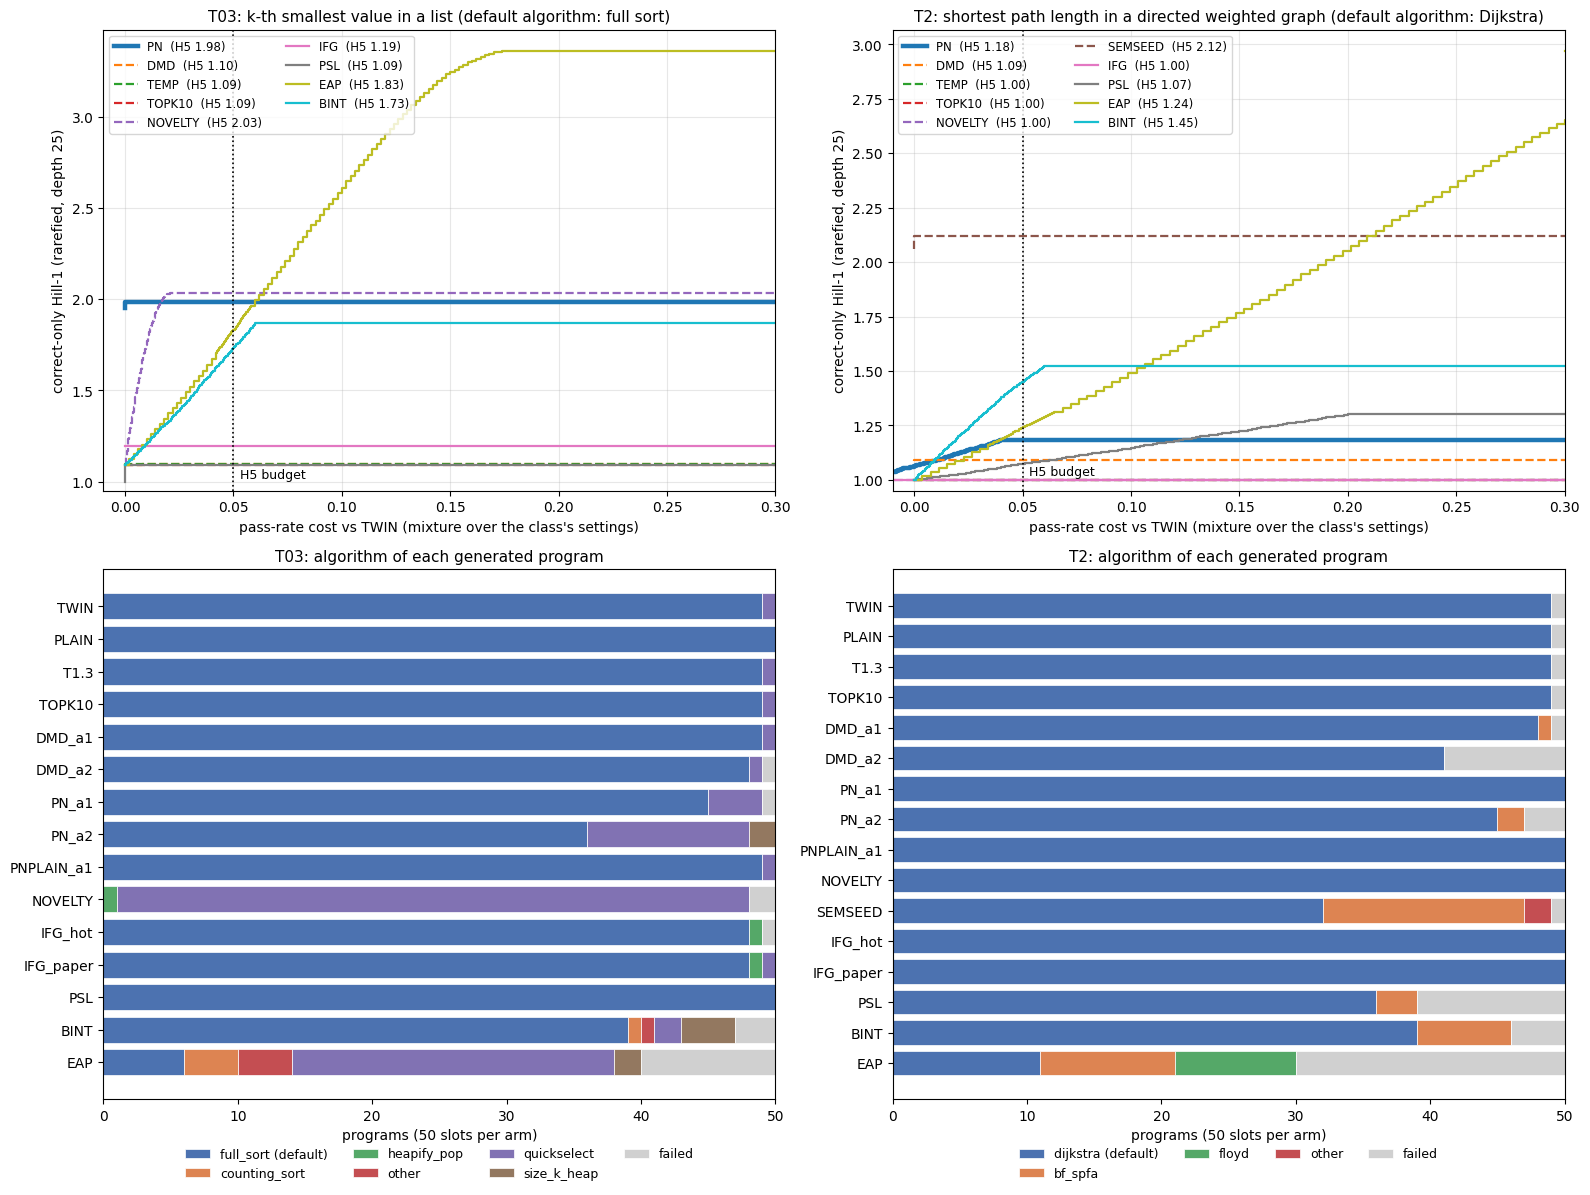

In [32]:
SHOW = ["PN", "DMD", "TEMP", "TOPK10", "NOVELTY", "SEMSEED", "IFG", "PSL", "EAP", "BINT"]
COL = dict(zip(SHOW, plt.cm.tab10.colors))
ARM_ORDER = ["TWIN", "PLAIN", "T1.3", "TOPK10", "DMD_a1", "DMD_a2", "PN_a1", "PN_a2", "PNPLAIN_a1", "NOVELTY",
             "SEMSEED", "IFG_hot", "IFG_paper", "PSL", "BINT", "EAP"]
fig, axes = plt.subplots(2, 2, figsize=(16, 12), gridspec_kw={"height_ratios": [1, 1.15]})
for j, t in enumerate(("T03", "T2")):
    ax = axes[0, j]
    for cls in SHOW:
        p = prices[t].get(cls)
        if not p or not p.get("frontier"):
            continue
        fr = np.array(p["frontier"], dtype=float)
        xs = np.concatenate([fr[:, 0], [0.30]])
        ys = np.concatenate([fr[:, 1], [fr[-1, 1]]])
        ax.step(xs, ys, where="post", color=COL[cls], lw=3.2 if cls == "PN" else 1.6,
                ls="-" if cls in ("PN", "IFG", "PSL", "EAP", "BINT") else "--", label=f"{cls}  (H5 {p['H5']:.2f})")
    ax.axvline(COST_BOUND, color="k", ls=":", lw=1.2)
    ax.text(COST_BOUND + 0.003, 1.02, "H5 budget", fontsize=9)
    ax.set_xlim(-0.01, 0.30)
    ax.set_ylim(0.95, None)
    ax.set_xlabel("pass-rate cost vs TWIN (mixture over the class's settings)")
    ax.set_ylabel("correct-only Hill-1 (rarefied, depth 25)")
    ax.set_title(f"{t}: {data['metadata']['tasks'][t]}", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper left", ncol=2)
    ax.grid(alpha=0.3)
    # bottom: composition of every arm's 50 programs
    ax = axes[1, j]
    d = dfl[t]["default"]
    arms = [a for a in ARM_ORDER if (t, a) in idx]
    labs_all = sorted({r["label"] for a in arms for r in idx[(t, a)].values() if r["passed"]} - {d})
    pal = [d] + labs_all
    lcol = {d: "#4c72b0", **{l: c for l, c in zip(labs_all, ["#dd8452", "#55a868", "#c44e52", "#8172b3", "#937860",
                                                               "#da8bc3", "#ccb974", "#64b5cd"])}}
    left = np.zeros(len(arms))
    for l in pal + ["failed"]:
        vals = np.array([sum(1 for r in idx[(t, a)].values() if (r["passed"] and r["label"] == l) or
                             (l == "failed" and not r["passed"])) for a in arms], dtype=float)
        ax.barh(range(len(arms)), vals, left=left, color=lcol.get(l, "#d0d0d0"), edgecolor="white", lw=0.5,
                label=l + (" (default)" if l == d else ""))
        left += vals
    ax.set_yticks(range(len(arms)))
    ax.set_yticklabels(arms)
    ax.invert_yaxis()
    ax.set_xlabel("programs (50 slots per arm)")
    ax.set_title(f"{t}: algorithm of each generated program", fontsize=11)
    ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### Figure 2: H5 with bootstrap intervals, and PN vs DMD at matched departure

- **Left**: each class's H5 (dots), with this run's bootstrap 95% interval (bars) and the committed point estimate
  (×). PN is in bold.
- **Right**: the share of the 50 slots that are correct **and** off-default, for PN, DMD (same per-token KL) and
  `TWIN`, at α 1 and α 2, with the exact McNemar test of PN vs DMD.

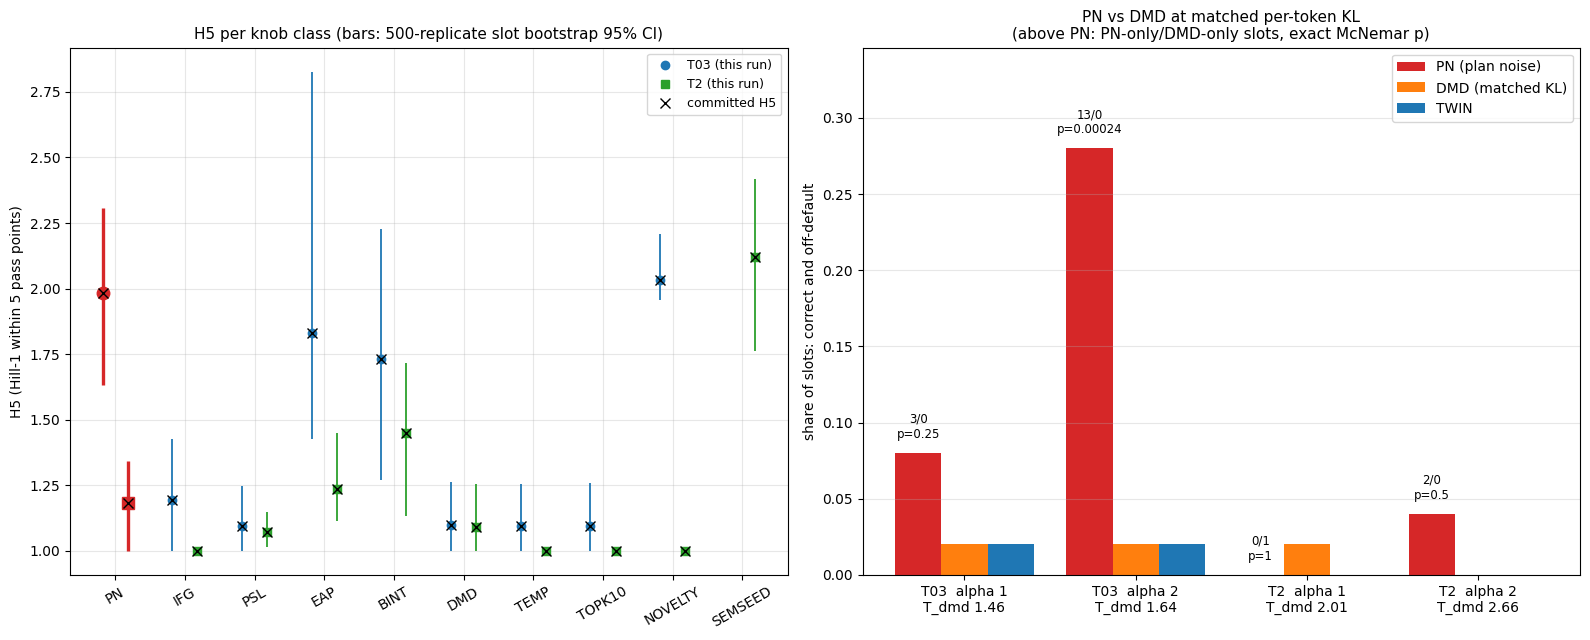

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ax = axes[0]
CLS = ["PN", "IFG", "PSL", "EAP", "BINT", "DMD", "TEMP", "TOPK10", "NOVELTY", "SEMSEED"]
for j, t in enumerate(("T03", "T2")):
    xs = [i + (j - 0.5) * 0.36 for i in range(len(CLS))]
    for x, c in zip(xs, CLS):
        if c not in kt[t]:
            continue
        lo, hi = kt[t][c]["H5_ci95"]
        h = kt[t][c]["H5"]
        col = "C3" if c == "PN" else ("C0" if t == "T03" else "C2")
        if lo is not None:
            ax.vlines(x, lo, hi, color=col, lw=2.4 if c == "PN" else 1.3)
        ax.plot(x, h, "o" if t == "T03" else "s", color=col, ms=9 if c == "PN" else 6,
                label=f"{t} (this run)" if c == "IFG" else None)
        ax.plot(x, ref["prices"][t][c]["H5"], "kx", ms=7, label="committed H5" if (c == "IFG" and t == "T2") else None)
ax.set_xticks(range(len(CLS)))
ax.set_xticklabels(CLS, rotation=30)
ax.set_ylabel("H5 (Hill-1 within 5 pass points)")
ax.set_title(f"H5 per knob class (bars: {len(boots['T03'])}-replicate slot bootstrap 95% CI)", fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
labels, pn_, dmd_, tw_, notes = [], [], [], [], []
for t in ("T03", "T2"):
    for a in ("1", "2"):
        m = pn_dmd["per_task"][t][f"alpha{a}"]
        labels.append(f"{t}  alpha {a}\nT_dmd {m['T_dmd']:.2f}")
        pn_.append(m["PN_off_default_share"]); dmd_.append(m["DMD_off_default_share"]); tw_.append(m["TWIN_off_default_share"])
        mc = m["mcnemar_PN_vs_DMD"]
        notes.append(f"{mc['x_only']}/{mc['y_only']}\np={mc['p_exact']:.2g}")
x = np.arange(len(labels))
ax.bar(x - 0.27, pn_, 0.27, color="C3", label="PN (plan noise)")
ax.bar(x, dmd_, 0.27, color="C1", label="DMD (matched KL)")
ax.bar(x + 0.27, tw_, 0.27, color="C0", label="TWIN")
for xi, n_, h in zip(x, notes, pn_):
    ax.text(xi - 0.27, h + 0.01, n_, ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, max(pn_ + dmd_ + tw_) * 1.2 + 0.01)
ax.set_ylabel("share of slots: correct and off-default")
ax.set_title("PN vs DMD at matched per-token KL\n(above PN: PN-only/DMD-only slots, exact McNemar p)", fontsize=11)
ax.legend(loc="upper right")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## Takeaways

- **Temperature is not the creativity knob here.**
  - Temperature 1.3 and top-k 10 leave both tasks at the default. On T03 they keep the single quickselect program
    that `TWIN` also writes (H5 1.09). On T2 every program is Dijkstra (H5 1.00).
  - DMD heats only the first 32 tokens, matched to plan noise's per-token KL, and does no better (H5 ≤ 1.10).
  - This agrees with the full run's literal cell (thinking on, top-k 10): 0 of 20 seeds change their algorithm
    across T ∈ {0.3, 0.7, 1.0, 1.3}.
- **Plan noise acts on the plan rather than on the tokens, but only on some tasks.**
  - `PN_a2` is a prefill-only nudge of 14–25 % of the hidden-state norm (α·r_Q). It turns 14 of the 50 T03 programs
    into quickselect or size-k heaps, at no pass cost (H5 1.98).
  - DMD at the same per-token KL does not: 13 PN-only vs 0 DMD-only slots, exact p = 0.0002.
  - On T2 the same nudge yields only 2 Bellman-Ford programs (H5 1.18).
- **Context that carries another algorithm moves T2 the most.**
  - The base-model intent (`BINT`) reaches H5 1.45.
  - Enumerate-and-pick reaches Hill ≈ 3 per cell, but loses 38 pass points to get there.
  - The semantic-seed story, whose paragraph describes relaxation in rounds, reaches H5 2.12 with 15 Bellman-Ford/SPFA
    programs.

  These are prompt-level pushes into another region of the model's repertoire. They do not produce new algorithms
  (see the caveat in section 8.8).
- **"Write a novel algorithm" swaps the default rather than diversifying.** On T03, 47 of the 48 correct programs
  become quickselect, the runner-up idea. On T2 all 50 programs stay Dijkstra.
- **Claim C on these two tasks.**
  - PN wins T03: 1.98 vs enumerate-and-pick's 1.83, but the bootstrap leaves it UNRESOLVED.
  - PN loses T2: 1.18 vs `BINT`'s 1.45.
  - That is 1 win of 2 against a threshold of 2: **DISCONFIRMED**, the same verdict as the committed 1 of 5 decisive
    tasks.
  - The independent re-derivation agrees on the verdict and on every McNemar count. The PN-as-TWIN placebo gives
    D_t ≤ 0, as it must.
- **Scope.** This demo covers 2 of the 5 decisive tasks and one model, Qwen3-8B, on memorised LeetCode-style tasks.
  The full verdict, its sensitivities and the literal cell are in the artifact's `results/` folder.